# Phát hiện vùng che logo / nhãn mác (thử nghiệm ngoài project)

**Mục tiêu:** tìm các vùng người bán cố ý che trên ảnh sản phẩm: dán sticker/emoji, tô trơn, quẹt cọ xóa logo, làm mờ nhãn, chữ đè lên logo.

**Cách làm (không cần gán nhãn tay để train):**
1. Lấy ảnh giày **sạch** (LazMall + OSLD trong `poc/data/logo_eval/images`, chỉ đọc). OWLv2 tìm vùng logo / nhãn / chữ trên giày.
2. **Sinh ảnh che tổng hợp** lên các vùng đó (và một số chỗ ngẫu nhiên trên giày). Mặt nạ vùng che có sẵn khi sinh, đó chính là nhãn.
3. Lấy đặc trưng **từng mảnh 14×14 px của DINOv2-base** (nối 3 tầng 4, 8, 12, để có cả đặc trưng cấp thấp như độ mờ, độ phẳng). Train một **MLP nhỏ** dự đoán mảnh nào bị che.
4. Đo trên **24 ảnh thật** trong `dataset/` (khung gán tay ở `annotations/real_boxes.json`, chỉ dùng để đo) và trên ảnh sạch giữ riêng (để đo báo nhầm).
5. So với luật OpenCV hiện tại của poc (`find_patches`).
6. Xuất dữ liệu tổng hợp dạng COCO để fine-tune detector (RF-DETR, Apache-2.0). Phần này tắt mặc định.

Kernel: `logo-obstruct (.venv)`, tức `D:\Code\logo-obstruct-detection\.venv`. GPU: RTX 3050 4 GB là đủ.

In [2]:
import json
import math
import random
import sys
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image, ImageDraw, ImageFilter, ImageFont

ROOT = Path.cwd() if (Path.cwd() / "dataset").exists() else Path(r"D:\Code\logo-obstruct-detection")
POC = Path(r"D:\Code\TH.AntiFakeExt\poc")            # chỉ ĐỌC model và ảnh sạch, không ghi gì vào poc
DINO_DIR = POC / "models" / "dinov2-base"
OWL_DIR = POC / "models" / "owlv2-base"
CLEAN_DIRS = [POC / "data/logo_eval/images/lazmall", POC / "data/logo_eval/images/osld", POC / "data/logo_eval/images/extension"]
EXCLUDE = ("2938144204",)  # niêm yết có logo bị dán che, trùng với img_* trong dataset/ → không dùng làm ảnh sạch
LOGODET_CLOTHES = Path(r"D:\Code\KGM\dataset\LogoDet-3K\Clothes")  # ảnh quần áo + khung logo (VOC); chỉ đọc
N_APPAREL = 450          # số ảnh áo lấy từ LogoDet-3K (logo nhỏ trên áo, không phải ảnh logo đồ họa)
REAL_DIR = ROOT / "dataset"
ANN = ROOT / "annotations" / "real_boxes.json"
WORK = ROOT / "work"
SYN_DIR = WORK / "synth"
for d in (WORK, SYN_DIR):
    d.mkdir(parents=True, exist_ok=True)

DEV = "cuda" if torch.cuda.is_available() else "cpu"
DT = torch.float16 if DEV == "cuda" else torch.float32
SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# Công thức dữ liệu sinh (xem bảng so các lượt ở cuối notebook):
#   tất cả False (+ USE_STORE) = lượt 6, đang dùng; tất cả False, USE_STORE = False = lượt 2
#   tất cả True  = lượt 5 (ít báo thừa trên ảnh áo, bắt được nhãn bị xóa chữ; sót sticker "HOT SALE" có chữ)
USE_APPAREL = False        # thêm ảnh áo LogoDet-3K/Clothes (lọc bằng OWLv2) làm nền
USE_LABEL_ERASE = False    # kiểu che: xóa / gạch chữ trên nhãn cổ, mác treo
USE_LABEL_NEG = False      # mẫu âm: nhãn nguyên vẹn ở cổ áo (chỉ ảnh áo)
USE_WATERMARK_NEG = False  # mẫu âm: dòng watermark tên shop
USE_STORE = True           # ảnh shop chính hãng Adidas/Nike (annotations/store_selection.json): train = nền + mẫu âm thật,
                           # val = chọn ngưỡng trên ảnh THẬT không che, test = đo báo thừa (mục 6c)
STORE_SEL = ROOT / "annotations" / "store_selection.json"
MAX_SIDE = 1024          # thu nhỏ ảnh lớn cho nhanh
VARIANTS_PER_IMAGE = 4   # số ảnh che tổng hợp mỗi ảnh sạch
VAL_FRAC = 0.2           # tỉ lệ ảnh sạch giữ riêng để đo
print("ROOT:", ROOT, "| device:", DEV, torch.cuda.get_device_name(0) if DEV == "cuda" else "")


def load_rgb(p, max_side=MAX_SIDE):
    im = Image.open(p).convert("RGB")
    s = max_side / max(im.size)
    if s < 1:
        im = im.resize((round(im.width * s), round(im.height * s)), Image.LANCZOS)
    return np.asarray(im)


def show(imgs, titles=None, cols=4, size=4):
    rows = math.ceil(len(imgs) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size, rows * size))
    for i, ax in enumerate(np.atleast_1d(axes).ravel()):
        ax.axis("off")
        if i < len(imgs):
            ax.imshow(imgs[i])
            if titles:
                ax.set_title(titles[i], fontsize=9)
    plt.tight_layout(); plt.show()

ROOT: d:\Code\logo-obstruct-detection | device: cuda NVIDIA GeForce RTX 3050 Laptop GPU


## 1. Ảnh thật và khung gán tay
89 khung trên 24 ảnh. Màu: tím = sticker, đỏ = tô trơn / quẹt cọ / xóa nhãn (`paint`), xanh dương = làm mờ (`blur`), xanh lá = chữ đè (`text_overlay`).
Ảnh `vn-…mjahvtxa…` trùng nội dung với `2aoborcgsaumscg…`. Ảnh này vẫn được tính khi đo nhưng có ghi chú.

24 ảnh, 89 khung: {'sticker': 34, 'paint': 44, 'text_overlay': 4, 'blur': 7}


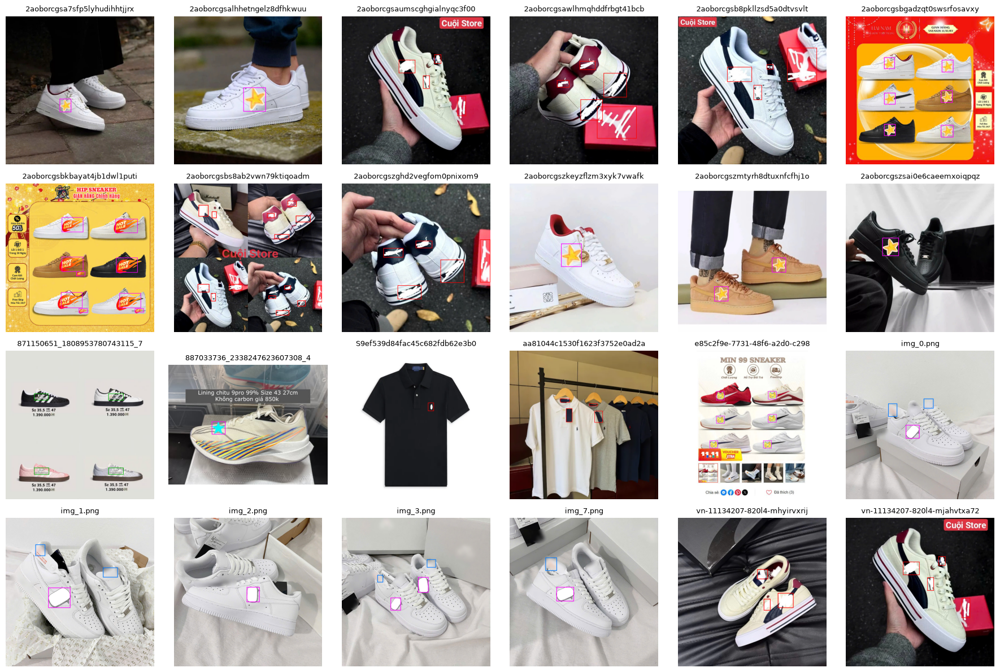

In [2]:
ann = json.loads(ANN.read_text(encoding="utf-8"))
REAL = ann["images"]
KIND_COLOR = {"sticker": (255, 0, 255), "paint": (255, 0, 0), "blur": (0, 120, 255), "text_overlay": (0, 170, 0)}


def draw_boxes(img, boxes, color_of=lambda b: KIND_COLOR[b["kind"]], width=None):
    im = Image.fromarray(img.copy()); d = ImageDraw.Draw(im)
    lw = width or max(2, im.width // 250)
    for b in boxes:
        d.rectangle(b["bbox"], outline=color_of(b), width=lw)
    return np.asarray(im)


real_imgs = {n: np.asarray(Image.open(REAL_DIR / n).convert("RGB")) for n in REAL}
from collections import Counter
print(len(REAL), "ảnh,", sum(len(v) for v in REAL.values()), "khung:",
      dict(Counter(b["kind"] for v in REAL.values() for b in v)))
show([draw_boxes(real_imgs[n], REAL[n]) for n in REAL], [n[:28] for n in REAL], cols=6, size=3)

## 2. Ảnh sạch và vùng mục tiêu (OWLv2)
OWLv2 (Apache-2.0, cùng model của poc) tìm giày (`shoe`) và các vùng logo / nhãn / chữ trên giày. Đây là chỗ sẽ dán vùng che tổng hợp.
Kết quả lưu vào `work/owl_targets.json`, chạy lại notebook sẽ không phải tính lại.

D:\Code\logo-obstruct-detection\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


ảnh sạch: 373 (train 299, val 74)
ảnh có giày: 358 / 373 | ảnh có vùng logo/nhãn: 344


  50/300 (646 ms/ảnh)


  100/300 (613 ms/ảnh)


  150/300 (598 ms/ảnh)


  200/300 (594 ms/ảnh)


  250/300 (603 ms/ảnh)


  300/300 (611 ms/ảnh)
ảnh shop chính hãng: train 300 · val (chọn ngưỡng) 60 · test (đo báo thừa) 150
thêm ảnh áo: 0 → train 599, val 74


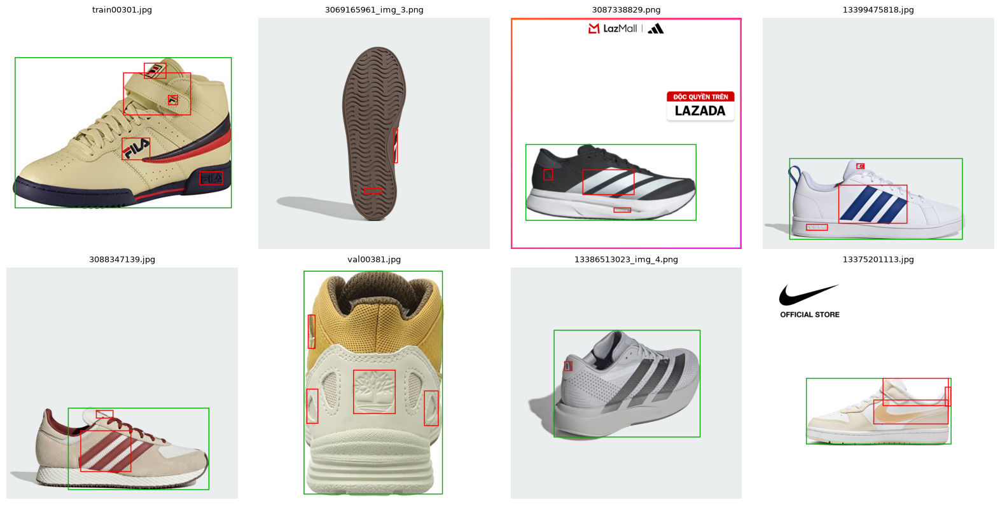

In [3]:
from transformers import Owlv2ForObjectDetection, Owlv2Processor

clean_paths = sorted(p for d in CLEAN_DIRS for p in d.iterdir()
                     if p.suffix.lower() in (".jpg", ".jpeg", ".png", ".webp") and not p.name.startswith(EXCLUDE))
random.Random(SEED).shuffle(clean_paths)
n_val = int(len(clean_paths) * VAL_FRAC)
val_paths, train_paths = clean_paths[:n_val], clean_paths[n_val:]
print(f"ảnh sạch: {len(clean_paths)} (train {len(train_paths)}, val {len(val_paths)})")

PHRASES = ["shoe", "logo", "brand logo", "swoosh logo", "three stripes logo", "label", "tag", "printed text"]
TARGET_CACHE = WORK / "owl_targets.json"


def box_iou(a, b):
    iw = max(0, min(a[2], b[2]) - max(a[0], b[0])); ih = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = iw * ih
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter + 1e-9)


def owl_targets(paths, prod_phrases=("shoe",)):
    """Sản phẩm = cụm từ trong prod_phrases (mặc định chỉ 'shoe'); vùng mục tiêu = cụm từ logo / nhãn / chữ."""
    phrases = list(prod_phrases) + PHRASES[1:]
    P = len(prod_phrases)
    proc = Owlv2Processor.from_pretrained(OWL_DIR)
    model = Owlv2ForObjectDetection.from_pretrained(OWL_DIR, dtype=DT).to(DEV).eval()
    tok = proc(text=[phrases], return_tensors="pt")
    out = {}
    t0 = time.time()
    for k, p in enumerate(paths):
        img = load_rgb(p)
        h, w = img.shape[:2]; S = max(h, w)
        pv = proc(images=Image.fromarray(img), return_tensors="pt")["pixel_values"].to(DEV, DT)
        with torch.inference_mode():
            o = model(input_ids=tok["input_ids"].to(DEV), attention_mask=tok["attention_mask"].to(DEV), pixel_values=pv)
        sc = o.logits[0].float().sigmoid().cpu().numpy()                 # (n_box, n_phrase)
        cx, cy, bw, bh = (o.pred_boxes[0].float().cpu().numpy() * S).T     # ảnh pad vuông ở dưới/phải
        boxes = np.stack([cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2], 1).clip(0, [w, h, w, h])
        ps = sc[:, :P].max(1)
        shoe = [(boxes[i].tolist(), float(ps[i])) for i in np.argsort(-ps)[:10] if ps[i] >= 0.2]
        prods = []
        for b, s in shoe:  # NMS đơn giản
            if all(box_iou(b, q) < 0.5 for q, _ in prods):
                prods.append((b, s))
        best = sc[:, P:].max(1)
        cand = []
        for i in np.argsort(-best):
            if best[i] < 0.08 or len(cand) >= 6:
                break
            b = boxes[i]
            area = (b[2] - b[0]) * (b[3] - b[1]) / (w * h)
            if area > 0.06 or min(b[2] - b[0], b[3] - b[1]) < 12:
                continue
            cxx, cyy = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2
            if prods and not any(q[0] <= cxx <= q[2] and q[1] <= cyy <= q[3] for q, _ in prods):
                continue
            if all(box_iou(b, q) < 0.3 for q, _ in cand):
                cand.append((b.tolist(), float(best[i])))
        out[str(p)] = {"size": [w, h], "products": prods, "targets": cand}
        if (k + 1) % 50 == 0:
            print(f"  {k + 1}/{len(paths)} ({(time.time() - t0) / (k + 1) * 1000:.0f} ms/ảnh)")
    del model; torch.cuda.empty_cache()
    return out


TARGETS = json.loads(TARGET_CACHE.read_text(encoding="utf-8")) if TARGET_CACHE.exists() else {}
missing = [p for p in clean_paths if str(p) not in TARGETS]
if missing:
    TARGETS.update(owl_targets(missing))
    TARGET_CACHE.write_text(json.dumps(TARGETS), encoding="utf-8")
print("ảnh có giày:", sum(bool(v["products"]) for v in TARGETS.values()), "/", len(TARGETS),
      "| ảnh có vùng logo/nhãn:", sum(bool(v["targets"]) for v in TARGETS.values()))

# --- Ảnh áo từ LogoDet-3K/Clothes: dùng khung logo có sẵn làm vùng mục tiêu, cả ảnh là "sản phẩm".
# Chỉ giữ ảnh cạnh ngắn ≥ 300 px và logo ≤ 8% diện tích (loại ảnh logo đồ họa chiếm cả khung).
import xml.etree.ElementTree as ET

APPAREL_CACHE = WORK / "apparel_targets.json"
if not USE_APPAREL:
    APP = {}
elif APPAREL_CACHE.exists():
    APP = json.loads(APPAREL_CACHE.read_text(encoding="utf-8"))
else:
    cand = []
    for xp in sorted(LOGODET_CLOTHES.glob("*/*.xml")):
        r = ET.parse(xp).getroot()
        W0, H0 = int(r.find("size/width").text), int(r.find("size/height").text)
        bs = [[int(float(o.find(k).text)) for k in ("xmin", "ymin", "xmax", "ymax")] for o in r.iter("bndbox")]
        jp = xp.with_suffix(".jpg")
        if (min(W0, H0) < 300 or not bs or not jp.exists()
                or max((b[2] - b[0]) * (b[3] - b[1]) for b in bs) / (W0 * H0) > 0.08
                or min(min(b[2] - b[0], b[3] - b[1]) for b in bs) < 10):
            continue
        cand.append((str(jp), W0, H0, bs))
    random.Random(SEED).shuffle(cand)
    # Lượt 3 cho thấy nhiều ảnh LogoDet là ảnh QUẢNG CÁO (poster, banner, huy hiệu) có sẵn đồ họa giống sticker;
    # gán chúng là "sạch" làm model quên sticker. Lọc bằng OWLv2: giữ ảnh có một chiếc áo chiếm ≥ 20% ảnh và logo nằm trên áo.
    GARMENT = ["a photo of a t-shirt", "a polo shirt", "a shirt", "a hoodie", "a jacket", "a sweater"]
    gproc = Owlv2Processor.from_pretrained(OWL_DIR)
    gmodel = Owlv2ForObjectDetection.from_pretrained(OWL_DIR, dtype=DT).to(DEV).eval()
    gtok = gproc(text=[GARMENT], return_tensors="pt")
    APP, checked = {}, 0
    for jp, W0, H0, bs in cand:
        if len(APP) >= N_APPAREL or checked >= 4 * N_APPAREL:
            break
        checked += 1
        img = load_rgb(jp)
        H, W = img.shape[:2]; s = W / W0; S = max(H, W)
        pv = gproc(images=Image.fromarray(img), return_tensors="pt")["pixel_values"].to(DEV, DT)
        with torch.inference_mode():
            o = gmodel(input_ids=gtok["input_ids"].to(DEV), attention_mask=gtok["attention_mask"].to(DEV), pixel_values=pv)
        sc = o.logits[0].float().sigmoid().max(-1).values.cpu().numpy()
        cx, cy, bw, bh = (o.pred_boxes[0].float().cpu().numpy() * S).T
        i = int(sc.argmax())
        g = [max(0, cx[i] - bw[i] / 2), max(0, cy[i] - bh[i] / 2), min(W, cx[i] + bw[i] / 2), min(H, cy[i] + bh[i] / 2)]
        tg = [[v * s for v in b] for b in bs]
        on = [b for b in tg if g[0] <= (b[0] + b[2]) / 2 <= g[2] and g[1] <= (b[1] + b[3]) / 2 <= g[3]]
        if sc[i] < 0.25 or (g[2] - g[0]) * (g[3] - g[1]) < 0.2 * W * H or not on:
            continue
        APP[jp] = {"size": [W, H], "products": [[[float(v) for v in g], float(sc[i])]],
                   "targets": [[b, 1.0] for b in on], "source": "logodet_clothes"}
    del gmodel; torch.cuda.empty_cache()
    APPAREL_CACHE.write_text(json.dumps(APP), encoding="utf-8")
    print(f"LogoDet-3K/Clothes: {len(cand)} ảnh đạt điều kiện cỡ logo; kiểm {checked} bằng OWLv2, giữ {len(APP)} ảnh áo thật")
TARGETS.update(APP)

# --- Ảnh shop chính hãng (Adidas, Nike): đã chọn sẵn bằng score_store_images.py + duyệt bằng mắt.
STORE = json.loads(STORE_SEL.read_text(encoding="utf-8")) if (USE_STORE and STORE_SEL.exists()) else {"train": [], "val": [], "test": []}
STORE_CACHE = WORK / "store_targets.json"
if STORE["train"]:
    ST = json.loads(STORE_CACHE.read_text(encoding="utf-8")) if STORE_CACHE.exists() else {}
    miss = [Path(p) for p in STORE["train"] if p not in ST]
    if miss:
        ST.update(owl_targets(miss, prod_phrases=("shoe", "a t-shirt", "a jacket", "pants", "shorts", "a dress", "a bag", "socks")))
        STORE_CACHE.write_text(json.dumps(ST), encoding="utf-8")
    TARGETS.update({p: ST[p] for p in STORE["train"]})
    train_paths = train_paths + [Path(p) for p in STORE["train"]]
print(f"ảnh shop chính hãng: train {len(STORE['train'])} · val (chọn ngưỡng) {len(STORE['val'])} · test (đo báo thừa) {len(STORE['test'])}")
app_paths = [Path(p) for p in APP]
n_app_val = int(len(app_paths) * VAL_FRAC)
val_paths, train_paths = val_paths + app_paths[:n_app_val], train_paths + app_paths[n_app_val:]
print(f"thêm ảnh áo: {len(app_paths)} → train {len(train_paths)}, val {len(val_paths)}")
if app_paths:
  show([draw_boxes(draw_boxes(load_rgb(p), [{"bbox": b} for b, _ in APP[str(p)]["products"]], lambda b: (0, 170, 0)),
                 [{"bbox": b} for b, _ in APP[str(p)]["targets"]], lambda b: (255, 0, 0)) for p in app_paths[:12]],
     [p.parent.name[:24] for p in app_paths[:12]], cols=6, size=3)

ex = train_paths[:8]
show([draw_boxes(load_rgb(p), [{"bbox": b} for b, _ in TARGETS[str(p)]["products"]], lambda b: (0, 170, 0))
      if not TARGETS[str(p)]["targets"] else
      draw_boxes(draw_boxes(load_rgb(p), [{"bbox": b} for b, _ in TARGETS[str(p)]["products"]], lambda b: (0, 170, 0)),
                 [{"bbox": b} for b, _ in TARGETS[str(p)]["targets"]], lambda b: (255, 0, 0)) for p in ex],
     [p.name[:24] for p in ex])

## 3. Bộ sinh vùng che tổng hợp
Mỗi kiểu che bắt chước một kiểu đã thấy trong ảnh thật:

| Kiểu | Mô phỏng | Ví dụ thật |
|---|---|---|
| `sticker` | sao, bong bóng chat, tròn, tim, mặt emoji, nhãn "HOT/SALE"; viền trắng kiểu sticker cắt, hoặc viền tối; có bóng đổ | sao vàng AF1, bong bóng trắng, mèo emoji, "HOT SALE" |
| `paint` | khối tô trơn một màu (trắng hoặc màu nền lấy quanh vùng) | pony Polo tô trắng, mác treo xóa trơn |
| `scribble` | nhiều nét cọ dày, mép răng cưa | formstrip Puma quẹt trắng, logo hộp |
| `blur` | Gaussian rất mạnh hoặc mosaic, mép mềm | tag lưỡi gà/gót AF1 |
| `text` | chữ/số điện thoại đè lên, có viền | "Zalo 0963…" đè lên Gazelle |
| `label_erase` | dán nhãn cổ / mác treo giả có chữ, rồi **tô màu nền nhãn lên phần chữ** hoặc **gạch chữ** (trắng/đỏ/hồng) | nhãn cổ Polo xóa trơn, chữ LACOSTE bị gạch hồng |

Thêm mẫu âm khó (sau lần đo dataset2):
- **nhãn cổ / mác treo nguyên vẹn** (có chữ, mã vạch), chỉ trên ảnh áo, ở vùng cổ áo; lượt trước model báo nhầm mác treo trắng của Lacoste. (Lượt 4 dán nhãn ở chỗ bất kỳ, kể cả giữa thân giày, làm model quên sticker.)
- **dòng watermark tên shop** lặp lại trải ngang ảnh (như "Cothi_shop").

Nền ảnh gồm giày (LazMall, OSLD, extension) và **áo** (LogoDet-3K/Clothes, khung logo có sẵn). LogoDet-3K chỉ dùng cho nghiên cứu, không dùng cho sản phẩm.

Thêm **mẫu âm khó** (gán nhãn KHÔNG che):
- banner/chữ shop đặt **ngoài** giày (giống "Cuội Store");
- **hậu cảnh mờ tự nhiên** (lấy nét nông: làm mờ mọi chỗ ngoài giày). Lượt chạy đầu cho thấy model nhầm hậu cảnh mờ, tường trơn, quần áo tối với vùng che.
Mọi ảnh (cả ảnh sạch) đều được nén JPEG lại ngẫu nhiên, để model không học được dấu vết nén.

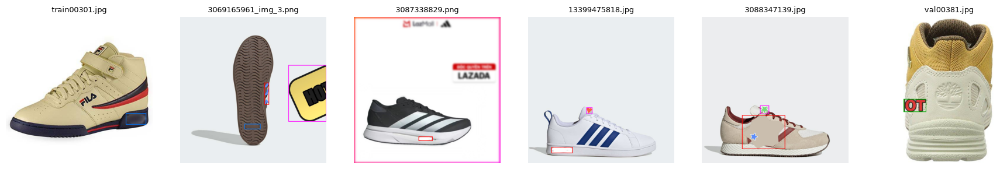

In [4]:
FONTS = [r"C:\Windows\Fonts\arialbd.ttf", r"C:\Windows\Fonts\arial.ttf", r"C:\Windows\Fonts\impact.ttf",
         r"C:\Windows\Fonts\segoeuib.ttf", r"C:\Windows\Fonts\comicbd.ttf", r"C:\Windows\Fonts\tahomabd.ttf"]
FONTS = [f for f in FONTS if Path(f).exists()]
PALETTE = [(255, 205, 40), (255, 170, 30), (255, 255, 255), (60, 230, 240), (255, 90, 60), (250, 120, 180),
           (120, 220, 120), (255, 230, 120), (240, 60, 60), (90, 140, 255)]
TEXTS = ["Zalo", "0963638613", "0912 345 678", "HOT", "SALE", "NEW", "Hàng chuẩn", "Shop uy tín", "Freeship",
         "Chính hãng", "1:1", "Best", "ORDER", "SALE 50%"]
KIND_P = ({"sticker": 0.25, "paint": 0.15, "scribble": 0.17, "blur": 0.13, "text": 0.12, "label_erase": 0.18} if USE_LABEL_ERASE
          else {"sticker": 0.30, "paint": 0.18, "scribble": 0.20, "blur": 0.17, "text": 0.15})   # tỉ lệ của lượt 2
KIND_TO_REAL = {"sticker": "sticker", "paint": "paint", "scribble": "paint", "blur": "blur", "text": "text_overlay",
                "label_erase": "paint"}


def _font(sz):
    return ImageFont.truetype(random.choice(FONTS), max(8, int(sz)))


def star_pts(cx, cy, ro, ri, rot, n=5):
    return [(cx + (ro if k % 2 == 0 else ri) * math.cos(rot + k * math.pi / n),
             cy + (ro if k % 2 == 0 else ri) * math.sin(rot + k * math.pi / n)) for k in range(2 * n)]


def sticker_rgba(w, h):
    """Một sticker RGBA cỡ (w, h), vẽ ở 4x rồi thu nhỏ để mép mượt."""
    W, H = int(w * 4), int(h * 4)
    shape = Image.new("L", (W, H), 0); sd = ImageDraw.Draw(shape)
    m = int(min(W, H) * 0.12)  # chừa chỗ cho viền
    kind = random.choice(["star", "bubble", "circle", "heart", "emoji", "badge", "rrect"])
    if kind == "star":
        sd.polygon(star_pts(W / 2, H / 2, min(W, H) / 2 - m, (min(W, H) / 2 - m) * random.uniform(0.38, 0.55),
                            random.uniform(0, 2 * math.pi)), fill=255)
    elif kind == "bubble":
        sd.rounded_rectangle([m, m, W - m, H - m * 2.2], radius=min(W, H) * 0.25, fill=255)
        tx = random.uniform(0.3, 0.8) * W
        sd.polygon([(tx - m, H - m * 2.4), (tx + m * 0.6, H - m * 2.4), (tx + m * 1.2, H - m * 0.8)], fill=255)
    elif kind in ("circle", "emoji"):
        sd.ellipse([m, m, W - m, H - m], fill=255)
    elif kind == "heart":
        r = (W - 2 * m) / 4
        sd.ellipse([m, m, m + 2 * r, m + 2 * r], fill=255); sd.ellipse([W - m - 2 * r, m, W - m, m + 2 * r], fill=255)
        sd.polygon([(m + r * 0.15, m + r * 1.3), (W - m - r * 0.15, m + r * 1.3), (W / 2, H - m)], fill=255)
    else:  # badge / rrect
        sd.rounded_rectangle([m, m, W - m, H - m], radius=min(W, H) * random.uniform(0.05, 0.4), fill=255)
    fill = random.choice(PALETTE)
    rgba = Image.new("RGBA", (W, H), (0, 0, 0, 0))
    border = random.random()

    def dilate(img_l, r):
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * r + 1, 2 * r + 1))
        return Image.fromarray(cv2.dilate(np.asarray(img_l), k))

    if border < 0.55:   # sticker cắt: viền trắng dày (+ có thể có bóng)
        rgba.paste((255, 255, 255, 255), mask=dilate(shape, max(1, int(min(W, H) * random.uniform(0.04, 0.09)))))
    elif border < 0.8:  # viền tối mảnh (bong bóng chat trên AF1)
        rgba.paste((random.randint(20, 80),) * 3 + (255,), mask=dilate(shape, max(1, int(min(W, H) * random.uniform(0.015, 0.035)))))
    body = Image.new("RGBA", (W, H), fill + (255,))
    if random.random() < 0.6:  # tô chuyển sắc nhẹ
        g = np.linspace(random.uniform(0.75, 1.0), random.uniform(1.0, 1.15), H)[:, None, None]
        arr = np.clip(np.asarray(body).astype(np.float32)[..., :3] * g, 0, 255).astype(np.uint8)
        body = Image.fromarray(np.dstack([arr, np.full((H, W), 255, np.uint8)]), "RGBA")
    rgba.paste(body, mask=shape)
    d = ImageDraw.Draw(rgba)
    if kind == "emoji":  # mắt + miệng
        e = min(W, H)
        for ex_ in (0.35, 0.65):
            d.ellipse([W * ex_ - e * 0.06, H * 0.38 - e * 0.08, W * ex_ + e * 0.06, H * 0.38 + e * 0.08], fill=(40, 30, 20, 255))
        d.arc([W * 0.3, H * 0.45, W * 0.7, H * 0.75], 20, 160, fill=(40, 30, 20, 255), width=max(2, int(e * 0.04)))
    if kind in ("badge", "rrect", "circle") and random.random() < 0.6:
        t = random.choice(TEXTS[3:])
        f = _font(H * 0.32)
        tw = d.textlength(t, font=f)
        if tw > W * 0.85:
            f = _font(H * 0.32 * W * 0.85 / tw)
        d.text((W / 2, H / 2), t, font=f, fill=random.choice([(255, 255, 255, 255), (200, 20, 20, 255), (30, 30, 30, 255)]),
               anchor="mm", stroke_width=max(1, int(H * 0.02)), stroke_fill=(0, 0, 0, 255))
    rgba = rgba.rotate(random.uniform(-35, 35), resample=Image.BICUBIC, expand=False)
    return rgba.resize((max(4, int(w)), max(4, int(h))), Image.LANCZOS)


def paste_rgba(img, rgba, x, y, shadow=False):
    base = Image.fromarray(img).convert("RGBA")
    if shadow:
        a = rgba.split()[3].filter(ImageFilter.GaussianBlur(max(1, rgba.width // 25)))
        sh = Image.new("RGBA", rgba.size, (0, 0, 0, 0)); sh.putalpha(a.point(lambda v: int(v * 0.35)))
        base.alpha_composite(sh, (int(x + rgba.width * 0.03), int(y + rgba.height * 0.04)))
    base.alpha_composite(rgba, (int(x), int(y)))
    mask = np.zeros(img.shape[:2], np.uint8)
    a = np.asarray(rgba.split()[3]) > 127
    x0, y0 = int(x), int(y)
    x1, y1 = min(img.shape[1], x0 + a.shape[1]), min(img.shape[0], y0 + a.shape[0])
    mask[max(0, y0):y1, max(0, x0):x1] = a[max(0, -y0):y1 - y0, max(0, -x0):x1 - x0]
    return np.asarray(base.convert("RGB")), mask


def grow(b, f, W, H):
    cx, cy, w, h = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2, (b[2] - b[0]) * f, (b[3] - b[1]) * f
    return [max(0, cx - w / 2), max(0, cy - h / 2), min(W, cx + w / 2), min(H, cy + h / 2)]


def ring_color(img, b):
    H, W = img.shape[:2]
    g = grow(b, 1.6, W, H); x0, y0, x1, y1 = map(int, g)
    patch = img[y0:y1, x0:x1].reshape(-1, 3)
    return tuple(int(v) for v in np.median(patch, 0)) if len(patch) else (255, 255, 255)


def blob_mask(shape, b, jag=0.25):
    """Đa giác bất quy tắc phủ khung b."""
    H, W = shape
    cx, cy, rx, ry = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2, (b[2] - b[0]) / 2, (b[3] - b[1]) / 2
    n = random.randint(10, 22)
    pts = [(cx + rx * (1 + random.uniform(-jag, jag)) * math.cos(t), cy + ry * (1 + random.uniform(-jag, jag)) * math.sin(t))
           for t in np.linspace(0, 2 * math.pi, n, endpoint=False)]
    m = np.zeros((H, W), np.uint8)
    cv2.fillPoly(m, [np.array(pts, np.int32)], 1)
    return m


def apply_obstruction(img, b, kind):
    H, W = img.shape[:2]
    bw, bh = b[2] - b[0], b[3] - b[1]
    if kind == "sticker":
        f = random.uniform(1.0, 1.6)
        s = max(bw, bh) * f * random.uniform(0.85, 1.15)
        sw, sh = s * random.uniform(0.8, 1.25), s * random.uniform(0.8, 1.25)
        cx, cy = (b[0] + b[2]) / 2 + random.uniform(-0.15, 0.15) * bw, (b[1] + b[3]) / 2 + random.uniform(-0.15, 0.15) * bh
        return paste_rgba(img, sticker_rgba(sw, sh), cx - sw / 2, cy - sh / 2, shadow=random.random() < 0.4)
    if kind == "paint":
        m = blob_mask((H, W), grow(b, random.uniform(1.05, 1.4), W, H), jag=random.uniform(0.05, 0.3))
        col = (255, 255, 255) if random.random() < 0.5 else ring_color(img, b)
        out = img.copy(); out[m > 0] = col
        if random.random() < 0.5:  # mép hơi mềm
            soft = cv2.GaussianBlur(m.astype(np.float32), (0, 0), 1.2)[..., None]
            out = (img * (1 - soft) + np.array(col) * soft).astype(np.uint8)
        return out, m
    if kind == "scribble":
        g = grow(b, random.uniform(1.0, 1.4), W, H)
        m = np.zeros((H, W), np.uint8)
        t = max(3, int(min(bw, bh) * random.uniform(0.12, 0.35)))
        n = random.randint(3, 9)
        horiz = random.random() < 0.5
        for k in range(n):
            u = (k + random.uniform(0, 1)) / n
            if horiz:
                p0 = (g[0] + random.uniform(-0.1, 0.1) * bw, g[1] + u * (g[3] - g[1]))
                p1 = (g[2] + random.uniform(-0.1, 0.1) * bw, g[1] + (u + random.uniform(-0.3, 0.3)) * (g[3] - g[1]))
            else:
                p0 = (g[0] + u * (g[2] - g[0]), g[1] + random.uniform(-0.1, 0.1) * bh)
                p1 = (g[0] + (u + random.uniform(-0.4, 0.4)) * (g[2] - g[0]), g[3] + random.uniform(-0.1, 0.1) * bh)
            mid = ((p0[0] + p1[0]) / 2 + random.uniform(-0.2, 0.2) * bw, (p0[1] + p1[1]) / 2 + random.uniform(-0.2, 0.2) * bh)
            pts = np.array([p0, mid, p1], np.int32)
            cv2.polylines(m, [pts], False, 1, thickness=int(t * random.uniform(0.6, 1.3)), lineType=cv2.LINE_AA)
        if random.random() < 0.5:
            m |= blob_mask((H, W), grow(b, 0.7, W, H), jag=0.4)
        m = cv2.dilate(m, np.ones((3, 3), np.uint8), iterations=random.randint(0, 2))
        col = (255, 255, 255) if random.random() < 0.75 else random.choice(PALETTE)
        out = img.copy(); out[m > 0] = col
        return out, m
    if kind == "blur":
        g = grow(b, random.uniform(1.1, 1.6), W, H)
        m = blob_mask((H, W), g, jag=0.1)
        if random.random() < 0.7:
            sig = max(3.0, max(bw, bh) * random.uniform(0.12, 0.3))
            eff = cv2.GaussianBlur(img, (0, 0), sig)
        else:
            x0, y0, x1, y1 = map(int, g)
            reg = img[y0:y1, x0:x1]
            k = random.randint(5, 10)  # số ô mosaic theo bề ngang
            small = cv2.resize(reg, (k, max(1, round(k * reg.shape[0] / max(1, reg.shape[1])))), interpolation=cv2.INTER_AREA)
            eff = img.copy(); eff[y0:y1, x0:x1] = cv2.resize(small, (reg.shape[1], reg.shape[0]), interpolation=cv2.INTER_NEAREST)
        soft = cv2.GaussianBlur(m.astype(np.float32), (0, 0), max(1.5, min(bw, bh) * 0.08))[..., None]
        return (img * (1 - soft) + eff * soft).astype(np.uint8), (soft[..., 0] > 0.5).astype(np.uint8)
    if kind == "text":
        lines = [random.choice(TEXTS) for _ in range(random.randint(1, 2))]
        fs = max(10, bh * random.uniform(0.5, 1.0) / len(lines))
        f = _font(fs)
        base = Image.fromarray(img).convert("RGBA")
        layer = Image.new("RGBA", base.size, (0, 0, 0, 0)); d = ImageDraw.Draw(layer)
        cx, cy = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2
        txt = "\n".join(lines)
        col = random.choice([(255, 255, 255), (255, 255, 255), (20, 20, 20), (230, 30, 30)])
        d.multiline_text((cx, cy), txt, font=f, fill=col + (random.randint(190, 255),), anchor="mm", align="center",
                         stroke_width=max(1, int(fs * 0.08)), stroke_fill=(0, 0, 0, 200) if col[0] > 128 else (255, 255, 255, 200))
        base.alpha_composite(layer)
        a = np.asarray(layer.split()[3]) > 60
        ys, xs = np.nonzero(a)
        m = np.zeros(img.shape[:2], np.uint8)
        if len(xs):  # nhãn = khối chữ (chữ mảnh, che theo cả khối)
            m[ys.min():ys.max() + 1, xs.min():xs.max() + 1] = 1
        return np.asarray(base.convert("RGB")), m
    raise ValueError(kind)


def offproduct_banner(img, prods):
    """Mẫu âm khó: banner chữ shop nằm NGOÀI giày (nhãn = không che)."""
    H, W = img.shape[:2]
    for _ in range(20):
        w, h = W * random.uniform(0.18, 0.4), H * random.uniform(0.05, 0.1)
        x, y = random.uniform(0, W - w), random.choice([random.uniform(0, H * 0.12), random.uniform(H * 0.85, H - h)])
        b = [x, y, x + w, y + h]
        if not any(box_iou(b, p) > 0.02 for p in prods):
            break
    else:
        return img
    im = Image.fromarray(img); d = ImageDraw.Draw(im)
    d.rounded_rectangle(b, radius=h * 0.25, fill=random.choice(PALETTE))
    t = random.choice(["Cuội Store", "HIP SNEAKER", "Sneaker Luxury", "Freeship 24/7", "Chính hãng 100%"])
    f = _font(h * 0.6)
    d.text(((b[0] + b[2]) / 2, (b[1] + b[3]) / 2), t, font=f, fill=(255, 255, 255), anchor="mm")
    return np.asarray(im)


def defocus_background(img, prods):
    """Mẫu âm khó: giữ nét vùng giày, làm mờ phần còn lại như ảnh chụp lấy nét nông (nhãn = không che)."""
    H, W = img.shape[:2]
    m = np.zeros((H, W), np.float32)
    for p in prods:
        x0, y0, x1, y1 = map(int, grow(p, 1.05, W, H)); m[y0:y1, x0:x1] = 1
    if not m.any():
        return img
    m = cv2.GaussianBlur(m, (0, 0), max(3, min(H, W) * 0.02))[..., None]
    bl = cv2.GaussianBlur(img, (0, 0), random.uniform(3, 10))
    return (img * m + bl * (1 - m)).astype(np.uint8)


def jpeg(img, q=None):
    q = q or random.randint(55, 95)
    ok, buf = cv2.imencode(".jpg", img[..., ::-1], [cv2.IMWRITE_JPEG_QUALITY, q])
    return cv2.imdecode(buf, cv2.IMREAD_COLOR)[..., ::-1].copy()


# ---------- Nhãn cổ / mác treo giả: dùng cho kiểu che "xóa chữ trên nhãn" và cho mẫu âm "nhãn nguyên vẹn" ----------
LABEL_WORDS = ["POLO", "RALPH LAUREN", "LACOSTE", "REGULAR FIT", "SLIM FIT", "CLASSIC FIT", "TOMMY", "HUGO BOSS",
               "M", "L", "XL", "100% COTTON", "MADE IN VIETNAM", "FR 3  US S", "ORIGINAL", "SPORT"]
LABEL_BG = [(25, 35, 80), (20, 20, 20), (240, 240, 235), (235, 225, 205), (250, 250, 250), (150, 20, 30), (60, 60, 60)]


def make_label(w, h, hang):
    """Nhãn cổ (hang=False) hoặc mác treo (hang=True) có chữ in. Trả về (RGB, mặt nạ chữ, màu nền)."""
    S = 3
    W_, H_ = max(9, int(w * S)), max(9, int(h * S))
    bg = random.choice(LABEL_BG)
    dark = sum(bg) < 300
    fg = random.choice([(245, 245, 245), (230, 200, 120)]) if dark else random.choice([(20, 20, 30), (30, 40, 90), (160, 20, 30)])
    im = Image.new("RGB", (W_, H_), bg); tm = Image.new("L", (W_, H_), 0)
    d, dm = ImageDraw.Draw(im), ImageDraw.Draw(tm)
    lines = [random.choice(LABEL_WORDS) for _ in range(random.randint(1, 3 if hang else 2))]
    fs = (H_ * 0.11 if hang else H_ * 0.55 / len(lines)) * random.uniform(0.9, 1.3)
    y = H_ * (random.uniform(0.15, 0.3) if hang else 0.5 - 0.5 * len(lines) * fs * 1.15 / H_)
    for t in lines:
        f = _font(fs)
        tw = d.textlength(t, font=f)
        if tw > 0.85 * W_:
            f = _font(fs * 0.85 * W_ / tw)
        for dd, col in ((d, fg), (dm, 255)):
            dd.text((W_ / 2, y), t, font=f, fill=col, anchor="mt")
        y += fs * 1.15
    if hang and random.random() < 0.7:  # mã vạch
        x = W_ * 0.15; y0, y1 = H_ * 0.65, H_ * 0.85
        while x < W_ * 0.85:
            bw = random.uniform(1, 4) * S
            if random.random() < 0.6:
                for dd, col in ((d, fg), (dm, 255)):
                    dd.rectangle([x, y0, x + bw, y1], fill=col)
            x += bw + random.uniform(1, 3) * S
    if hang and random.random() < 0.5:  # lỗ xỏ dây / chấm đỏ
        d.ellipse([W_ / 2 - W_ * 0.06, H_ * 0.04, W_ / 2 + W_ * 0.06, H_ * 0.04 + W_ * 0.12], fill=random.choice([(200, 30, 30), (220, 220, 220)]))
    lab = np.asarray(im.resize((max(3, int(w)), max(3, int(h))), Image.LANCZOS))
    tmask = np.asarray(tm.resize((max(3, int(w)), max(3, int(h))), Image.BILINEAR)) > 60
    return lab, tmask, bg


def place_label(img, cx, cy, w, h, hang):
    lab, tm, bg = make_label(w, h, hang)
    ang = random.uniform(-25, 25)
    rgba = Image.fromarray(lab).convert("RGBA").rotate(ang, resample=Image.BICUBIC, expand=True)
    tmr = np.asarray(Image.fromarray(tm.astype(np.uint8) * 255).rotate(ang, resample=Image.BILINEAR, expand=True)) > 100
    x0, y0 = int(cx - rgba.width / 2), int(cy - rgba.height / 2)
    out, lmask = paste_rgba(img, rgba, x0, y0, shadow=random.random() < 0.5)
    H, W = img.shape[:2]
    tmask = np.zeros((H, W), np.uint8)
    x1, y1 = min(W, x0 + tmr.shape[1]), min(H, y0 + tmr.shape[0])
    if x1 > max(0, x0) and y1 > max(0, y0):
        tmask[max(0, y0):y1, max(0, x0):x1] = tmr[max(0, -y0):y1 - y0, max(0, -x0):x1 - x0]
    return out, lmask, tmask, bg


def random_spot(prods, W, H, w, h):
    p = random.choice(prods) if prods else [0, 0, W, H]
    return (random.uniform(p[0] + w / 2, max(p[0] + w / 2, p[2] - w / 2)),
            random.uniform(p[1] + h / 2, max(p[1] + h / 2, p[3] - h / 2)))


def label_size(prods, W, H, hang):
    p = random.choice(prods) if prods else [0, 0, W, H]
    w = max(30, min(p[2] - p[0], p[3] - p[1]) * random.uniform(0.08, 0.22))
    return w, w * (random.uniform(1.4, 2.2) if hang else random.uniform(0.25, 0.45))


def label_erase(img, prods):
    """Kiểu che: dán nhãn/mác có chữ rồi XÓA chữ (tô màu nền nhãn đè lên) hoặc GẠCH chữ. Nhãn = vùng bị tô/gạch."""
    H, W = img.shape[:2]
    hang = random.random() < 0.5
    w, h = label_size(prods, W, H, hang)
    out, lmask, tmask, bg = place_label(img, *random_spot(prods, W, H, w, h), w, h, hang)
    ys, xs = np.nonzero(tmask)
    if len(xs) < 10:
        return out, np.zeros((H, W), np.uint8)
    tb = [xs.min(), ys.min(), xs.max() + 1, ys.max() + 1]
    if random.random() < 0.65:  # tô màu nền nhãn lên phần chữ (nhãn còn nguyên màu, chỉ mất chữ)
        m = blob_mask((H, W), grow(tb, random.uniform(1.1, 1.4), W, H), jag=random.uniform(0.0, 0.15)) & lmask.astype(np.uint8)
        col = np.clip(np.array(bg) + np.random.randint(-12, 13, 3), 0, 255)
        out = out.copy()
        if random.random() < 0.5:
            soft = cv2.GaussianBlur(m.astype(np.float32), (0, 0), 1.0)[..., None]
            out = (out * (1 - soft) + col * soft).astype(np.uint8)
        else:
            out[m > 0] = col
    else:  # gạch ngang chữ bằng nét cọ trắng / đỏ / hồng
        m = np.zeros((H, W), np.uint8)
        t = max(3, int((tb[3] - tb[1]) * random.uniform(0.15, 0.4)))
        for _ in range(random.randint(1, 3)):
            yy = random.uniform(tb[1], tb[3])
            cv2.line(m, (int(tb[0] - 4), int(yy + random.uniform(-t, t))), (int(tb[2] + 4), int(yy + random.uniform(-t, t))), 1, t, cv2.LINE_AA)
        col = random.choice([(255, 255, 255), (235, 30, 120), (220, 30, 30)])
        out = out.copy(); out[m > 0] = col
    return out, m


def add_labels(img, prods, n, apparel):
    """Mẫu âm khó: nhãn cổ / mác treo NGUYÊN VẸN (có chữ, mã vạch).

    Chỉ đặt trên ẢNH ÁO, ở vùng cổ áo (phần trên của khung áo, quanh giữa), vì đó là chỗ nhãn thật nằm.
    Lượt 4 đặt nhãn ở chỗ bất kỳ (cả giữa thân giày) → nhãn trông như sticker có chữ, model quên sticker.
    """
    if not apparel or not prods:
        return img
    H, W = img.shape[:2]
    p = max(prods, key=lambda q: (q[2] - q[0]) * (q[3] - q[1]))
    pw, ph = p[2] - p[0], p[3] - p[1]
    for _ in range(n):
        hang = random.random() < 0.6
        w, h = label_size([p], W, H, hang)
        cx = p[0] + pw * random.uniform(0.38, 0.62)
        cy = p[1] + ph * (random.uniform(0.04, 0.15) if not hang else random.uniform(0.15, 0.35)) + h / 2 * hang
        img, _, _, _ = place_label(img, cx, min(H - h / 2, cy), w, h, hang)
    return img


def watermark(img):
    """Mẫu âm khó: dòng watermark tên shop lặp lại trải ngang ảnh (như 'Cothi_shop')."""
    H, W = img.shape[:2]
    im = Image.fromarray(img).convert("RGBA")
    layer = Image.new("RGBA", im.size, (0, 0, 0, 0)); d = ImageDraw.Draw(layer)
    t = random.choice(["Cothi_shop", "shop_xinh", "Sneaker.vn", "hangauth_store", "@fashion.hn", "Kho_si_HN"])
    fs = max(10, int(H * random.uniform(0.018, 0.035))); f = _font(fs)
    unit = random.choice(["• ", "* ", "", "~ "]) + t + "   "
    for _ in range(random.choice([1, 1, 2])):
        x, y = random.uniform(-fs * 5, 0), random.uniform(0.15, 0.85) * H
        a = random.randint(140, 230)
        while x < W:
            d.text((x, y), unit, font=f, fill=(255, 255, 255, a), stroke_width=random.choice([0, 0, 1]), stroke_fill=(0, 0, 0, a // 2))
            x += d.textlength(unit, font=f)
    im.alpha_composite(layer)
    return np.asarray(im.convert("RGB"))


def add_distractors(img, prods, apparel, p_labels=0.6, p_wm=0.3):
    # kiểm công tắc TRƯỚC khi gọi random, để công thức lượt 2 dùng đúng chuỗi số ngẫu nhiên như lượt 2
    if USE_LABEL_NEG and random.random() < p_labels:
        img = add_labels(img, prods, random.randint(1, 2), apparel)
    if USE_WATERMARK_NEG and random.random() < p_wm:
        img = watermark(img)
    return img


def synthesize(img, info, rng_targets=True):
    """Trả về (ảnh, mặt nạ che, danh sách {bbox, kind})."""
    H, W = img.shape[:2]
    prods = [p for p, _ in info["products"]]
    tg = [t for t, _ in info["targets"]]
    if random.random() < 0.3:
        img = defocus_background(img, prods)
    apparel = info.get("source") == "logodet_clothes"
    if USE_LABEL_NEG and random.random() < 0.5:  # nhãn nguyên vẹn (chỉ ảnh áo, ở cổ áo) đặt TRƯỚC vùng che
        img = add_labels(img, prods, random.randint(1, 2), apparel)
    n = random.choice([1, 1, 1, 2, 2, 3])
    picks = []
    for _ in range(n):
        if tg and random.random() < 0.75:
            b = random.choice(tg)
        else:  # chỗ ngẫu nhiên trên giày (để không chỉ học "che = nằm trên logo")
            p = random.choice(prods) if prods else [0, 0, W, H]
            s = min(p[2] - p[0], p[3] - p[1]) * random.uniform(0.1, 0.3)
            x, y = random.uniform(p[0], max(p[0], p[2] - s)), random.uniform(p[1], max(p[1], p[3] - s))
            b = [x, y, x + s * random.uniform(0.7, 1.5), y + s]
        if all(box_iou(b, q) < 0.2 for q, _ in picks):
            picks.append((b, random.choices(list(KIND_P), weights=KIND_P.values())[0]))
    out, full = img.copy(), np.zeros((H, W), np.uint8)
    objs = []
    for b, k in picks:
        out, m = label_erase(out, prods) if k == "label_erase" else apply_obstruction(out, b, k)
        m = m.astype(bool) & ~full.astype(bool)
        full |= m.astype(np.uint8)
        ys, xs = np.nonzero(m)
        if len(xs) > 30:
            objs.append({"bbox": [int(xs.min()), int(ys.min()), int(xs.max()) + 1, int(ys.max()) + 1], "kind": k})
    if random.random() < 0.3:
        out = offproduct_banner(out, prods)
    if USE_WATERMARK_NEG and random.random() < 0.3:  # watermark shop: không tính là che
        out = watermark(out)
    return jpeg(out), full, objs


random.seed(1)
demo = ([p for p in train_paths if TARGETS[str(p)]["targets"] and str(p) not in APP][:6]
        + [p for p in train_paths if str(p) in APP][:6])
demo_out = []
for p in demo:
    im, m, objs = synthesize(load_rgb(p), TARGETS[str(p)])
    demo_out.append(draw_boxes(im, [{"bbox": o["bbox"], "kind": KIND_TO_REAL[o["kind"]]} for o in objs]))
show(demo_out, [p.name[:24] for p in demo], cols=6, size=3)

### Sinh toàn bộ tập train / val
Mỗi ảnh sạch tạo `VARIANTS_PER_IMAGE` ảnh che, và giữ 1 bản sạch (đã nén lại JPEG) làm mẫu âm.
Ảnh và mặt nạ lưu ở `work/synth/`. Nhãn khung dạng COCO lưu ở `work/synth_{train,val}.json`, dùng cho phần RF-DETR.

In [5]:
def build_split(paths, split, variants):
    recs = []
    for k, p in enumerate(paths):
        info = TARGETS[str(p)]
        base = load_rgb(p)
        for v in range(variants + 1):
            if v == variants:  # ảnh sạch: một nửa có hậu cảnh mờ, có thể có nhãn/mác nguyên vẹn, watermark shop
                prods = [q for q, _ in info["products"]]
                b2 = defocus_background(base, prods) if random.random() < 0.5 else base
                b2 = add_distractors(b2, prods, info.get("source") == "logodet_clothes")
                img, mask, objs = jpeg(b2), np.zeros(base.shape[:2], np.uint8), []
            else:
                img, mask, objs = synthesize(base, info)
            stem = f"{split}_{k:04d}_{p.stem[:20]}_{v}"   # ảnh LogoDet trùng tên giữa các hãng (1.jpg, 2.jpg…)
            Image.fromarray(img).save(SYN_DIR / f"{stem}.jpg", quality=95)
            cv2.imwrite(str(SYN_DIR / f"{stem}_mask.png"), mask * 255)
            recs.append({"stem": stem, "src": str(p), "clean": v == variants, "objs": objs,
                         "size": [img.shape[1], img.shape[0]]})
    return recs


random.seed(SEED); np.random.seed(SEED)
for f in SYN_DIR.glob("*"):  # xóa ảnh tổng hợp của lần chạy trước
    f.unlink()
t0 = time.time()
SYN = {"train": build_split(train_paths, "train", VARIANTS_PER_IMAGE),
       "val": build_split(val_paths, "val", VARIANTS_PER_IMAGE)}
for split, recs in SYN.items():
    print(split, len(recs), "ảnh,", sum(len(r["objs"]) for r in recs), "vùng che:",
          dict(Counter(o["kind"] for r in recs for o in r["objs"])))
print(f"{time.time() - t0:.0f} s")


def to_coco(recs, path):
    cats = list(KIND_P)
    coco = {"images": [], "annotations": [], "categories": [{"id": i, "name": c} for i, c in enumerate(["obstruction"])]}
    aid = 0
    for i, r in enumerate(recs):
        coco["images"].append({"id": i, "file_name": f"{r['stem']}.jpg", "width": r["size"][0], "height": r["size"][1]})
        for o in r["objs"]:
            x0, y0, x1, y1 = o["bbox"]
            coco["annotations"].append({"id": aid, "image_id": i, "category_id": 0, "bbox": [x0, y0, x1 - x0, y1 - y0],
                                        "area": (x1 - x0) * (y1 - y0), "iscrowd": 0, "attributes": {"kind": o["kind"]}})
            aid += 1
    path.write_text(json.dumps(coco), encoding="utf-8")


for split, recs in SYN.items():
    to_coco(recs, WORK / f"synth_{split}.json")

train 2995 ảnh, 3465 vùng che: {'scribble': 693, 'sticker': 1035, 'blur': 587, 'paint': 639, 'text': 511}
val 370 ảnh, 411 vùng che: {'sticker': 126, 'paint': 73, 'blur': 62, 'text': 66, 'scribble': 84}
640 s


## 4. Đặc trưng từng mảnh của DINOv2 (+ MLP nhỏ)
- Ảnh được letterbox về 518×518, tức lưới 37×37 mảnh, mỗi mảnh 14 px.
- Đặc trưng mỗi mảnh = nối tầng 4, 8, 12 của DINOv2-base (2.304 chiều). Tầng thấp giữ dấu hiệu "phẳng / mờ / mép cắt", tầng cao hiểu "sticker / chữ".
- Nhãn mảnh: bị che nếu ≥ 30% diện tích mảnh nằm trong mặt nạ; không che nếu ≤ 2%; ở giữa thì bỏ qua.
- Mỗi ảnh lấy mọi mảnh dương và tối đa 150 mảnh âm, để vừa RAM.

In [6]:
from transformers import AutoModel

SIZE, PATCH = 518, 14
G = SIZE // PATCH
LAYERS = (4, 8, 12)
MEAN = np.array([0.485, 0.456, 0.406], np.float32); STD = np.array([0.229, 0.224, 0.225], np.float32)
dino = AutoModel.from_pretrained(DINO_DIR, dtype=DT).to(DEV).eval()


def letterbox(img, interp=cv2.INTER_AREA, pad=0):
    h, w = img.shape[:2]; s = SIZE / max(h, w)
    nh, nw = round(h * s), round(w * s)
    r = cv2.resize(img, (nw, nh), interpolation=interp)
    out = np.full((SIZE, SIZE) + img.shape[2:], pad, img.dtype)
    out[:nh, :nw] = r
    return out, s, (nh, nw)


def valid_grid(nh, nw):
    v = np.zeros((G, G), bool); v[:math.ceil(nh / PATCH), :math.ceil(nw / PATCH)] = True
    return v


@torch.inference_mode()
def dino_patch_feats(imgs, bs=8):
    """imgs: list ảnh RGB (đã letterbox 518). Trả về (N, G*G, 768*len(LAYERS)) float16 trên CPU."""
    out = []
    for i in range(0, len(imgs), bs):
        x = (np.stack(imgs[i:i + bs]).astype(np.float32) / 255 - MEAN) / STD
        x = torch.from_numpy(x).permute(0, 3, 1, 2).to(DEV, DT)
        hs = dino(pixel_values=x, output_hidden_states=True).hidden_states
        f = torch.cat([hs[l][:, 1:] for l in LAYERS], -1)
        out.append(f.half().cpu())
    return torch.cat(out)


def patch_cover(mask_lb):
    return mask_lb.reshape(G, PATCH, G, PATCH).mean((1, 3))


NEG_PER_IMG = 150


def collect(recs, neg_per_img=NEG_PER_IMG):
    X, Y, IDX = [], [], []
    for i in range(0, len(recs), 32):
        chunk = recs[i:i + 32]
        lbs, covs, vals = [], [], []
        for r in chunk:
            img = np.asarray(Image.open(SYN_DIR / f"{r['stem']}.jpg"))
            m = cv2.imread(str(SYN_DIR / f"{r['stem']}_mask.png"), cv2.IMREAD_GRAYSCALE) // 255
            lb, s, (nh, nw) = letterbox(img)
            mlb, _, _ = letterbox(m.astype(np.float32), cv2.INTER_AREA)
            lbs.append(lb); covs.append(patch_cover(mlb)); vals.append(valid_grid(nh, nw))
        F = dino_patch_feats(lbs)
        for j, r in enumerate(chunk):
            cov, val = covs[j].ravel(), vals[j].ravel()
            pos = np.nonzero(val & (cov >= 0.3))[0]
            neg = np.nonzero(val & (cov <= 0.02))[0]
            if len(neg) > neg_per_img:
                neg = np.random.choice(neg, neg_per_img, replace=False)
            sel = np.concatenate([pos, neg])
            X.append(F[j, sel]); Y.append(np.r_[np.ones(len(pos)), np.zeros(len(neg))]); IDX.append(np.full(len(sel), i + j))
    return torch.cat(X), torch.from_numpy(np.concatenate(Y)).float(), np.concatenate(IDX)


t0 = time.time()
np.random.seed(SEED)
Xtr, Ytr, _ = collect(SYN["train"])
Xva, Yva, Iva = collect(SYN["val"], neg_per_img=250)
print(f"train {tuple(Xtr.shape)} (dương {int(Ytr.sum())}) · val {tuple(Xva.shape)} (dương {int(Yva.sum())}) · {time.time() - t0:.0f} s")

train (541094, 2304) (dương 91844) · val (105064, 2304) (dương 12564) · 251 s


### Train MLP
MLP 2.304 → 256 → 1, BCE có cân lớp, AdamW, 10 epoch. Chạy GPU mất vài giây.

In [7]:
import torch.nn as nn
from sklearn.metrics import average_precision_score, roc_auc_score

def mean_std(X, chunk=65536):
    s = torch.zeros(X.shape[1], dtype=torch.float64); s2 = torch.zeros_like(s)
    for k in range(0, len(X), chunk):
        c = X[k:k + chunk].double(); s += c.sum(0); s2 += (c * c).sum(0)
    m = s / len(X)
    return m.float(), (s2 / len(X) - m ** 2).clamp_min(0).sqrt().float() + 1e-4


mu, sd = mean_std(Xtr)


class Probe(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, 256), nn.GELU(), nn.Dropout(0.2), nn.Linear(256, 1))
        self.register_buffer("mu", mu.clone()); self.register_buffer("sd", sd.clone())

    def forward(self, x):
        return self.net((x.float() - self.mu) / self.sd).squeeze(-1)


torch.manual_seed(SEED)
probe = Probe(Xtr.shape[1]).to(DEV)
opt = torch.optim.AdamW(probe.parameters(), lr=1e-3, weight_decay=1e-2)
pw = ((len(Ytr) - Ytr.sum()) / Ytr.sum()).to(DEV)
lossf = nn.BCEWithLogitsLoss(pos_weight=pw)
# Dữ liệu train để trên RAM, mỗi batch mới đưa lên GPU (GPU 4 GB không chứa hết)
for ep in range(10):
    probe.train(); perm = torch.randperm(len(Ytr)); tot = 0
    for k in range(0, len(perm), 4096):
        b = perm[k:k + 4096]
        xb, yb = Xtr[b].to(DEV, non_blocking=True), Ytr[b].to(DEV)
        loss = lossf(probe(xb), yb)
        opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(b)
    probe.eval()
    with torch.no_grad():
        pv = torch.cat([probe(Xva[k:k + 8192].to(DEV)).sigmoid().cpu() for k in range(0, len(Xva), 8192)]).numpy()
    print(f"epoch {ep + 1}: loss {tot / len(Ytr):.4f} · val AUC {roc_auc_score(Yva, pv):.4f} · AP {average_precision_score(Yva, pv):.4f}")
torch.cuda.empty_cache()
torch.save(probe.state_dict(), WORK / "probe.pt")

epoch 1: loss 0.1600 · val AUC 0.9956 · AP 0.9852


epoch 2: loss 0.0752 · val AUC 0.9967 · AP 0.9875


epoch 3: loss 0.0533 · val AUC 0.9966 · AP 0.9876


epoch 4: loss 0.0398 · val AUC 0.9971 · AP 0.9891


epoch 5: loss 0.0317 · val AUC 0.9969 · AP 0.9882


epoch 6: loss 0.0240 · val AUC 0.9962 · AP 0.9870


epoch 7: loss 0.0222 · val AUC 0.9965 · AP 0.9879


epoch 8: loss 0.0170 · val AUC 0.9968 · AP 0.9883


epoch 9: loss 0.0148 · val AUC 0.9966 · AP 0.9877


epoch 10: loss 0.0130 · val AUC 0.9968 · AP 0.9888


## 5. Từ bản đồ mảnh ra khung, chọn ngưỡng
- Bản đồ xác suất 37×37 → phóng về ảnh gốc → lấy thành phần liên thông có xác suất ≥ ngưỡng → khung.
- **Lọc theo vùng sản phẩm (`GATE`)**: OWLv2 tìm sản phẩm (giày, áo, túi), và chỉ giữ xác suất bên trong khung sản phẩm (nới 8%). Bước này loại hậu cảnh, quần áo người mẫu, tường. Mất đi vùng che trên **hộp giày** (7/89 khung thật).
- **Ngưỡng chọn trên ảnh sạch của val** (không che), sao cho khoảng ≤ 10% ảnh sạch có một khung báo che. Như vậy ngưỡng không chạm tới ảnh thật. Ngưỡng được chọn riêng cho từng chế độ (có lọc / không lọc).

In [8]:
@torch.no_grad()
def heatmap(img):
    lb, s, (nh, nw) = letterbox(img)
    p = probe(dino_patch_feats([lb])[0].to(DEV)).sigmoid().cpu().numpy().reshape(G, G)
    p[~valid_grid(nh, nw)] = 0
    return p, s, (nh, nw)


def heat_to_full(p, s, nh_nw, shape):
    nh, nw = nh_nw
    up = cv2.resize(p, (SIZE, SIZE), interpolation=cv2.INTER_LINEAR)[:nh, :nw]
    return cv2.resize(up, (shape[1], shape[0]), interpolation=cv2.INTER_LINEAR)


PRODUCT_PHRASES = ["shoe", "sneaker", "shirt", "clothing", "bag"]
owl_proc = Owlv2Processor.from_pretrained(OWL_DIR)
owl = Owlv2ForObjectDetection.from_pretrained(OWL_DIR, dtype=DT).to(DEV).eval()
gate_tok = owl_proc(text=[PRODUCT_PHRASES], return_tensors="pt")
_gate_cache = {}


@torch.inference_mode()
def product_gate(img, key=None, thr=0.15):
    """Mặt nạ 0/1: hợp các khung sản phẩm (OWLv2), nới 8%. Không thấy sản phẩm → cả ảnh."""
    if key is not None and key in _gate_cache:
        return _gate_cache[key]
    h, w = img.shape[:2]; S = max(h, w)
    pv = owl_proc(images=Image.fromarray(img), return_tensors="pt")["pixel_values"].to(DEV, DT)
    o = owl(input_ids=gate_tok["input_ids"].to(DEV), attention_mask=gate_tok["attention_mask"].to(DEV), pixel_values=pv)
    sc = o.logits[0].float().sigmoid().max(-1).values.cpu().numpy()
    cx, cy, bw, bh = (o.pred_boxes[0].float().cpu().numpy() * S).T
    g = np.zeros((h, w), np.float32)
    for i in np.nonzero(sc >= thr)[0]:
        if bw[i] * bh[i] < 0.02 * w * h:
            continue
        x0, y0, x1, y1 = map(int, grow([cx[i] - bw[i] / 2, cy[i] - bh[i] / 2, cx[i] + bw[i] / 2, cy[i] + bh[i] / 2], 1.08, w, h))
        g[y0:y1, x0:x1] = 1
    if not g.any():
        g[:] = 1
    if key is not None:
        _gate_cache[key] = g
    return g


def full_heat(img, gate, key=None):
    p, s, nn_ = heatmap(img)
    full = heat_to_full(p, s, nn_, img.shape)
    return full * product_gate(img, key) if gate else full


def boxes_from_heat(full, thr, min_area_frac=0.0004):
    m = (full >= thr).astype(np.uint8)
    n, lab, st, _ = cv2.connectedComponentsWithStats(m)
    H, W = full.shape
    out = []
    for i in range(1, n):
        x, y, w, h, a = st[i]
        if a >= min_area_frac * H * W:
            out.append({"bbox": [int(x), int(y), int(x + w), int(y + h)], "score": float(full[lab == i].max())})
    return out


val_clean = [r for r in SYN["val"] if r["clean"]]
# Ngưỡng: nếu có ảnh shop chính hãng (val), chọn trên ẢNH THẬT không che; nếu không, trên ảnh sạch tổng hợp.
if STORE["val"]:
    clean_set = [(p, lambda p=p: load_rgb(p)) for p in STORE["val"]]
    clean_name = "ảnh shop chính hãng (val, thật)"
else:
    clean_set = [(r["stem"], lambda r=r: np.asarray(Image.open(SYN_DIR / f"{r['stem']}.jpg"))) for r in val_clean]
    clean_name = "ảnh sạch tổng hợp (val)"
THRS = {}
for gate in (False, True):
    clean_max = np.array([full_heat(get(), gate, key).max() for key, get in clean_set])
    THRS[gate] = min(max(float(np.quantile(clean_max, 0.90)), 0.5), 0.98)
    print(f"{'CÓ lọc vùng sản phẩm' if gate else 'KHÔNG lọc'}: {clean_name} {len(clean_max)} · ngưỡng = {THRS[gate]:.3f}")
    for t in (0.5, 0.7, 0.9, THRS[gate]):
        print(f"  ngưỡng {t:.2f}: {np.mean(clean_max >= t):.0%} ảnh sạch bị báo che")
GATE = True
THR = THRS[GATE]

KHÔNG lọc: ảnh shop chính hãng (val, thật) 60 · ngưỡng = 0.940
  ngưỡng 0.50: 67% ảnh sạch bị báo che
  ngưỡng 0.70: 57% ảnh sạch bị báo che
  ngưỡng 0.90: 33% ảnh sạch bị báo che
  ngưỡng 0.94: 10% ảnh sạch bị báo che


CÓ lọc vùng sản phẩm: ảnh shop chính hãng (val, thật) 60 · ngưỡng = 0.921
  ngưỡng 0.50: 55% ảnh sạch bị báo che
  ngưỡng 0.70: 48% ảnh sạch bị báo che
  ngưỡng 0.90: 25% ảnh sạch bị báo che
  ngưỡng 0.92: 10% ảnh sạch bị báo che


### Đo trên ảnh tổng hợp của val (theo kiểu che)
Một vùng che "bắt được" nếu xác suất lớn nhất trong khung ≥ ngưỡng.

In [9]:
def hit_rate(recs_or_real, get_img, get_boxes, thr, gate=GATE):
    hits = Counter(); tot = Counter(); fa = 0; n_img = 0; heat_cache = {}
    for idx, key in enumerate(recs_or_real):
        img = get_img(key)
        k = key if isinstance(key, str) else key["stem"]
        full = full_heat(img, gate, k)
        heat_cache[key if isinstance(key, str) else idx] = full
        gts = get_boxes(key)
        for g in gts:
            x0, y0, x1, y1 = map(int, g["bbox"])
            ok = full[y0:y1, x0:x1].max() >= thr if (x1 > x0 and y1 > y0) else False
            hits[g["kind"]] += ok; tot[g["kind"]] += 1
        for d in boxes_from_heat(full, thr):
            if not any(box_iou(d["bbox"], grow(g["bbox"], 1.3, img.shape[1], img.shape[0])) > 0 for g in gts):
                fa += 1
        n_img += 1
    return hits, tot, fa, n_img, heat_cache


val_obs = [r for r in SYN["val"] if not r["clean"]]
h, t, fa, n, _ = hit_rate(val_obs, lambda r: np.asarray(Image.open(SYN_DIR / f"{r['stem']}.jpg")), lambda r: r["objs"], THR)
print(f"Val tổng hợp ({n} ảnh), ngưỡng {THR:.2f}:")
for k in KIND_P:
    print(f"  {k:9s} bắt được {h[k]}/{t[k]} = {h[k] / max(1, t[k]):.0%}")
print(f"  tổng {sum(h.values())}/{sum(t.values())} = {sum(h.values()) / sum(t.values()):.0%} · khung báo thừa: {fa} ({fa / n:.2f}/ảnh)")

Val tổng hợp (296 ảnh), ngưỡng 0.92:
  sticker   bắt được 126/126 = 100%
  paint     bắt được 64/73 = 88%
  scribble  bắt được 82/84 = 98%
  blur      bắt được 54/62 = 87%
  text      bắt được 65/66 = 98%
  tổng 391/411 = 95% · khung báo thừa: 8 (0.03/ảnh)


## 6. Đo trên 24 ảnh thật
Các ảnh này chưa từng được dùng khi train hay khi chọn ngưỡng.

Ảnh thật, KHÔNG lọc (24 ảnh, 89 khung), ngưỡng 0.94:
  sticker      bắt được 30/34 = 88%
  paint        bắt được 36/44 = 82%
  blur         bắt được 7/7 = 100%
  text_overlay bắt được 3/4 = 75%
  tổng 76/89 = 85% · chỉ trên sản phẩm 69/82 · khung báo thừa: 19 (0.79/ảnh)


Ảnh thật, CÓ lọc vùng sản phẩm (24 ảnh, 89 khung), ngưỡng 0.92:
  sticker      bắt được 30/34 = 88%
  paint        bắt được 34/44 = 77%
  blur         bắt được 7/7 = 100%
  text_overlay bắt được 4/4 = 100%
  tổng 75/89 = 84% · chỉ trên sản phẩm 70/82 · khung báo thừa: 16 (0.67/ảnh)
Ghi chú: khung trên hộp giày (packaging): 7 | ảnh trùng: {'vn-11134207-820l4-mjahvtxa72the5@resize_w900_nl.webp': '2aoborcgsaumscghgialnyqc3f00bnmmu7ix4ue02.jpg'}


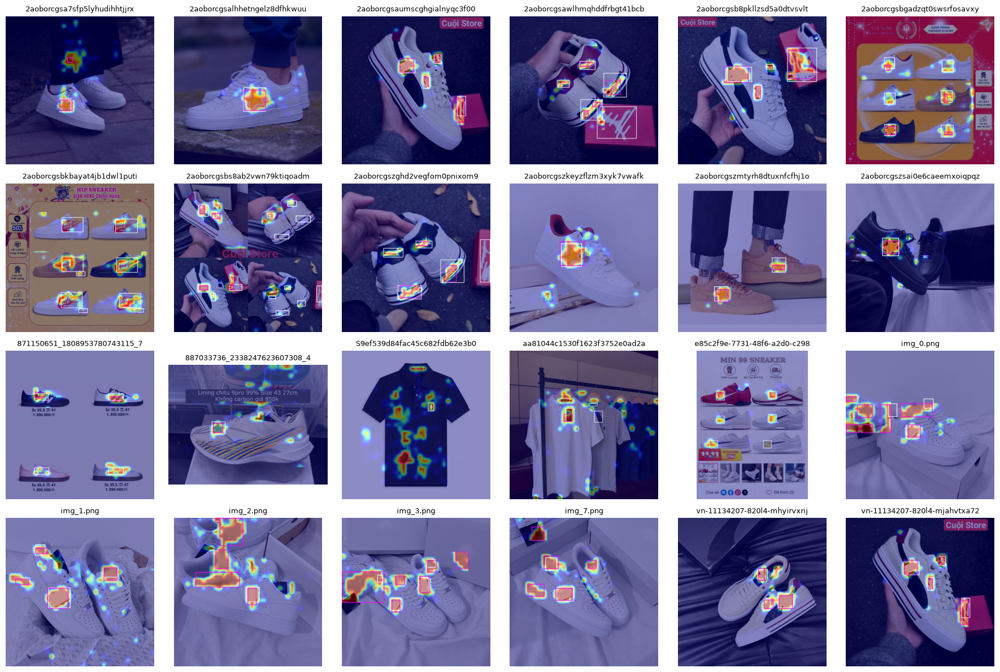

In [10]:
REAL_NAMES = list(REAL)
for gate in (False, True):
    thr = THRS[gate]
    h, t, fa, n, heat = hit_rate(REAL_NAMES, lambda k: real_imgs[k], lambda k: REAL[k], thr, gate)
    hp, tp, _, _, _ = hit_rate(REAL_NAMES, lambda k: real_imgs[k], lambda k: [g for g in REAL[k] if g["on"] == "product"], thr, gate)
    print(f"Ảnh thật, {'CÓ lọc vùng sản phẩm' if gate else 'KHÔNG lọc'} ({n} ảnh, {sum(t.values())} khung), ngưỡng {thr:.2f}:")
    for k in KIND_COLOR:
        print(f"  {k:12s} bắt được {h[k]}/{t[k]} = {h[k] / max(1, t[k]):.0%}")
    print(f"  tổng {sum(h.values())}/{sum(t.values())} = {sum(h.values()) / sum(t.values()):.0%} · "
          f"chỉ trên sản phẩm {sum(hp.values())}/{sum(tp.values())} · khung báo thừa: {fa} ({fa / n:.2f}/ảnh)")
    if gate == GATE:
        HEAT = heat
print("Ghi chú: khung trên hộp giày (packaging):", sum(g["on"] == "packaging" for k in REAL for g in REAL[k]),
      "| ảnh trùng:", ann.get("duplicates"))


def overlay(img, full, gts, dets):
    hm = (plt.cm.jet(np.clip(full, 0, 1))[..., :3] * 255).astype(np.uint8)
    out = (img * 0.55 + hm * 0.45).astype(np.uint8)
    out = draw_boxes(out, gts, lambda b: (255, 255, 255))
    return draw_boxes(out, dets, lambda b: (255, 0, 255))


show([overlay(real_imgs[k], HEAT[k], REAL[k], boxes_from_heat(HEAT[k], THR)) for k in REAL_NAMES],
     [k[:28] for k in REAL_NAMES], cols=6, size=3)

Khung **trắng** = gán tay, khung **tím** = model báo (ngưỡng đã chọn). Nền màu là bản đồ xác suất (đỏ = cao).

## 6b. Đo trên dataset2 (áo Polo Ralph Lauren / Lacoste)
20 ảnh, 75 khung gán tay (`annotations/dataset2_boxes.json`). Kiểu che gồm: mảng trắng đè lên logo/nhãn, nhãn cổ và mác treo bị xóa trơn, nét gạch trắng/hồng/đỏ.
**Đây là miền khác hẳn:** model chỉ học trên ảnh giày. Dùng nguyên model và ngưỡng ở trên, không chỉnh gì.
Watermark "Cothi_shop" của shop không được gán là che. Nếu model báo ở đó thì tính là báo thừa.

20 ảnh, 75 khung, 3 khung trên túi giấy


KHÔNG lọc, ngưỡng 0.94: bắt được 56/75 = 75% · chỉ trên sản phẩm 54/72 · ảnh có ≥1 vùng che bị phát hiện 17/20 · khung báo thừa 14 (0.70/ảnh)


CÓ lọc vùng sản phẩm, ngưỡng 0.92: bắt được 59/75 = 79% · chỉ trên sản phẩm 57/72 · ảnh có ≥1 vùng che bị phát hiện 18/20 · khung báo thừa 16 (0.80/ảnh)


  (ngưỡng 0.5: bắt 66/75, báo thừa 78)


  (ngưỡng 0.7: bắt 63/75, báo thừa 36)


  (ngưỡng 0.9: bắt 60/75, báo thừa 13)


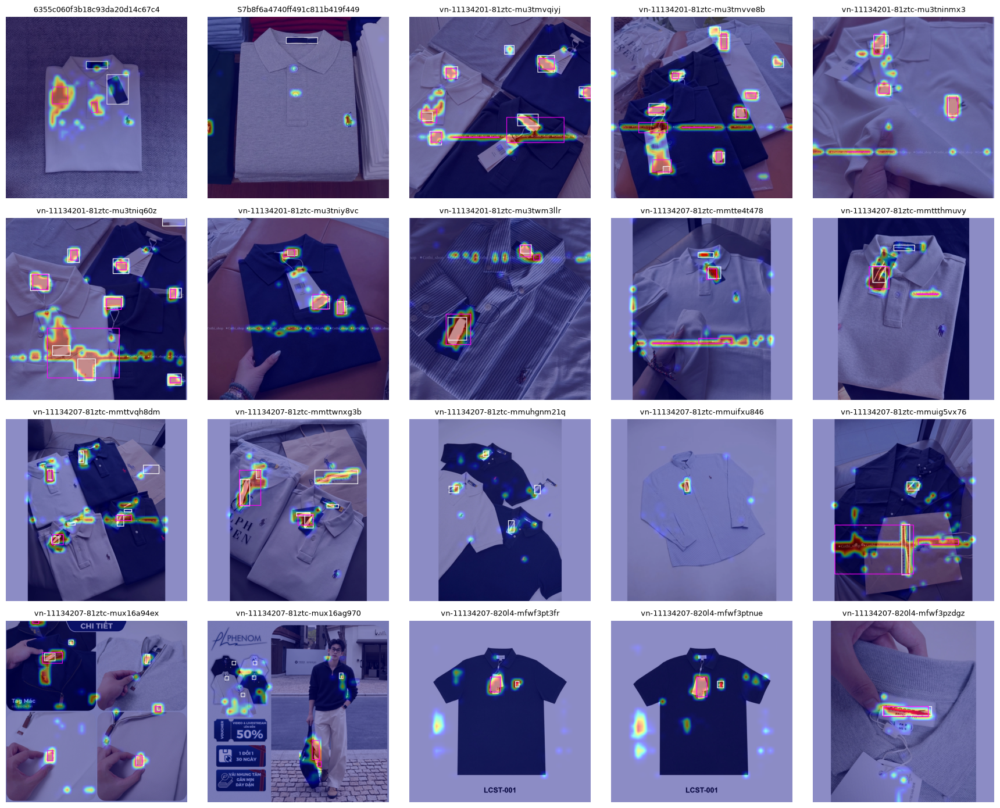

In [11]:
ANN2 = ROOT / "annotations" / "dataset2_boxes.json"
REAL2 = json.loads(ANN2.read_text(encoding="utf-8"))["images"]
real2_imgs = {n: np.asarray(Image.open(ROOT / "dataset2" / n).convert("RGB")) for n in REAL2}
REAL2_NAMES = list(REAL2)
print(len(REAL2), "ảnh,", sum(len(v) for v in REAL2.values()), "khung,",
      sum(g["on"] == "packaging" for v in REAL2.values() for g in v), "khung trên túi giấy")
for gate in (False, True):
    thr = THRS[gate]
    h, t, fa, n, heat = hit_rate(REAL2_NAMES, lambda k: real2_imgs[k], lambda k: REAL2[k], thr, gate)
    hp, tp, _, _, _ = hit_rate(REAL2_NAMES, lambda k: real2_imgs[k], lambda k: [g for g in REAL2[k] if g["on"] == "product"], thr, gate)
    per_img = sum(any(full_heat(real2_imgs[k], gate, k)[int(g["bbox"][1]):int(g["bbox"][3]), int(g["bbox"][0]):int(g["bbox"][2])].max() >= thr
                      for g in REAL2[k]) for k in REAL2_NAMES)
    print(f"{'CÓ lọc vùng sản phẩm' if gate else 'KHÔNG lọc'}, ngưỡng {thr:.2f}: bắt được {sum(h.values())}/{sum(t.values())} "
          f"= {sum(h.values()) / sum(t.values()):.0%} · chỉ trên sản phẩm {sum(hp.values())}/{sum(tp.values())} · "
          f"ảnh có ≥1 vùng che bị phát hiện {per_img}/{n} · khung báo thừa {fa} ({fa / n:.2f}/ảnh)")
    if gate == GATE:
        HEAT2 = heat
for t_ in (0.5, 0.7, 0.9):
    hh, tt, ff, _, _ = hit_rate(REAL2_NAMES, lambda k: real2_imgs[k], lambda k: REAL2[k], t_, GATE)
    print(f"  (ngưỡng {t_:.1f}: bắt {sum(hh.values())}/{sum(tt.values())}, báo thừa {ff})")
show([overlay(real2_imgs[k], HEAT2[k], REAL2[k], boxes_from_heat(HEAT2[k], THR)) for k in REAL2_NAMES],
     [k[:28] for k in REAL2_NAMES], cols=5, size=3.5)

## 6c. Báo thừa trên ảnh shop chính hãng giữ riêng (test, không che)
Ảnh Adidas / Nike official store chưa dùng khi train hay chọn ngưỡng (chia theo cụm mã sản phẩm). Mọi khung model báo ở đây đều là báo thừa.

ngưỡng 0.900: 48/150 ảnh (32%) có khung báo thừa · tổng 8 khung


ngưỡng 0.921: 40/150 ảnh (27%) có khung báo thừa · tổng 7 khung


ngưỡng 0.940: 23/150 ảnh (15%) có khung báo thừa · tổng 7 khung


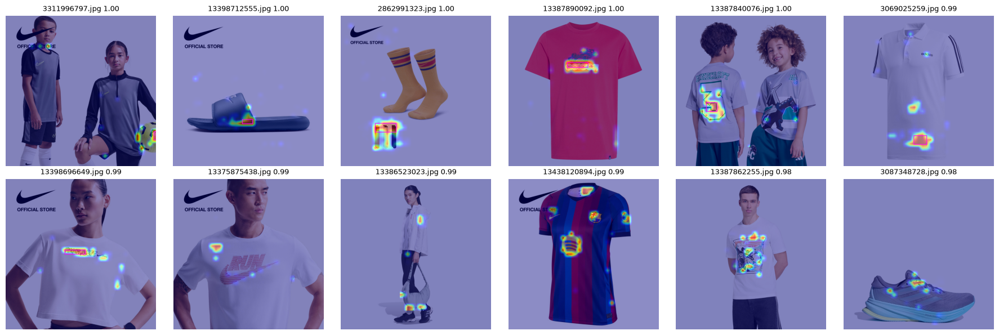

In [12]:
if STORE["test"]:
    st_heat = {p: full_heat(load_rgb(p), GATE, p) for p in STORE["test"]}
    for t_ in sorted({0.9, 0.94, round(THR, 3)}):
        n_img = sum(h.max() >= t_ for h in st_heat.values())
        n_box = sum(len(boxes_from_heat(h, t_)) for h in st_heat.values())
        print(f"ngưỡng {t_:.3f}: {n_img}/{len(st_heat)} ảnh ({n_img / len(st_heat):.0%}) có khung báo thừa · tổng {n_box} khung")
    worst = sorted(st_heat, key=lambda p: -st_heat[p].max())[:12]
    show([overlay(load_rgb(p), st_heat[p], [], boxes_from_heat(st_heat[p], THR)) for p in worst],
         [f"{Path(p).name[:16]} {st_heat[p].max():.2f}" for p in worst], cols=6, size=3)
else:
    print("Không có ảnh shop (USE_STORE = False hoặc thiếu annotations/store_selection.json)")

## 7. So với luật OpenCV hiện tại của poc (`find_patches`)
Luật dò "mảng phẳng do phần mềm tô / làm mờ" trên toàn ảnh, với ngưỡng như `configs/pipeline.yaml` (chỉ đọc code poc).
Ở đây chỉ chạy phần dò mảng, chưa có bước lọc theo vùng giày của OWLv2. Kết quả vì vậy là cận trên về độ bắt và cận trên về báo thừa.

In [13]:
try:
    sys.path.insert(0, str(POC / "src"))
    import yaml
    from abcd_poc.logo_obscured import PatchConfig, find_patches
    pcfg = PatchConfig.from_dict(yaml.safe_load((POC / "configs/pipeline.yaml").read_text(encoding="utf-8"))["logo_obscured"]["patch"])
    hits = Counter(); tot = Counter(); fa = 0
    for k in REAL_NAMES:
        ps = find_patches(real_imgs[k], pcfg)
        for g in REAL[k]:
            tot[g["kind"]] += 1
            hits[g["kind"]] += any(box_iou(p.bbox, g["bbox"]) > 0.1 for p in ps)
        fa += sum(not any(box_iou(p.bbox, g["bbox"]) > 0.1 for g in REAL[k]) for p in ps)
    print("Luật OpenCV hiện tại trên ảnh thật:")
    for k in KIND_COLOR:
        print(f"  {k:12s} bắt được {hits[k]}/{tot[k]}")
    print(f"  tổng {sum(hits.values())}/{sum(tot.values())} · khung báo thừa: {fa}")
except Exception as e:  # thiếu pyyaml hoặc poc đổi cấu trúc
    print("Bỏ qua so sánh:", type(e).__name__, e)

Luật OpenCV hiện tại trên ảnh thật:
  sticker      bắt được 6/34
  paint        bắt được 4/44
  blur         bắt được 0/7
  text_overlay bắt được 0/4
  tổng 10/89 · khung báo thừa: 29


## 8. Fine-tune detector RF-DETR (chạy ngoài notebook)
Dữ liệu COCO do mục 3 xuất ra (`work/synth_{train,val}.json`, 1 lớp `obstruction`, kiểu che ở `attributes.kind`) được dùng bởi hai script:

```
.venv\Scripts\python.exe -X utf8 rfdetr_train.py --bench        # đo tốc độ, ước tính thời gian train
.venv\Scripts\python.exe -X utf8 rfdetr_train.py --epochs 20    # train → work/rfdetr_out/
.venv\Scripts\python.exe -X utf8 rfdetr_eval.py                 # đo trên dataset/, dataset2/, shop test (cùng thước đo với probe)
```
RF-DETR (Roboflow, Apache-2.0, backbone DINOv2) bản small, batch 2 × cộng dồn 8 cho GPU 4 GB.

## Ghi chú
- **Nhãn ảnh thật là khung xấp xỉ** (±20 px), chỉ dùng để đo "có bắt được vùng đó không", không đo độ khít khung.
- 24 ảnh đều có che. Báo thừa trên ảnh sạch được đo trên ảnh val sạch (LazMall/OSLD), khác miền với ảnh chụp tay của shop nhỏ.
- **Khoảng cách miền**: ảnh sạch phần lớn là ảnh studio nền trắng, ảnh thật là ảnh chụp tay hoặc ảnh ghép quảng cáo. Nếu kết quả trên ảnh thật kém hơn hẳn val tổng hợp, cần thêm ảnh sạch kiểu chụp tay làm nền để sinh dữ liệu.
- OSLD có license CC BY-NC 4.0: chỉ dùng cho thử nghiệm, không dùng cho sản phẩm.

## 9. Thử trên ảnh bất kỳ
**Chạy độc lập:** chỉ cần chạy **ô cấu hình đầu tiên** rồi chạy ô dưới. Model đọc từ `work/probe.pt`, không phải train lại.

Cách chọn ảnh (chọn một hoặc nhiều cách cùng lúc rồi bấm **Phân tích**):
- **Ảnh có sẵn:** danh sách ảnh trong `dataset/`, `dataset2/` và ảnh shop test;
- **Đường dẫn:** dán đường dẫn một ảnh trên máy;
- **Tải ảnh lên:** chọn một hoặc nhiều file.

Nếu giao diện không hiện (JupyterLab chưa cài `jupyterlab_widgets`), gọi `for f in chon_file(): phan_tich(f)`. Hàm này mở hộp chọn file của Windows.

Kết quả: ảnh gốc, bản đồ xác suất kèm khung vùng nghi bị che (số trên khung = điểm), và bảng các vùng.
Đây chỉ là **tín hiệu sàng lọc** "có dấu hiệu che logo/nhãn", không phải kết luận.

In [4]:
import io
import math
import os

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from PIL import Image, ImageDraw

T_PROBE = WORK / "probe.pt"
T_SIZE, T_PATCH, T_LAYERS = 518, 14, (4, 8, 12)
T_G = T_SIZE // T_PATCH
T_MEAN = np.array([0.485, 0.456, 0.406], np.float32); T_STD = np.array([0.229, 0.224, 0.225], np.float32)
T_GATE_PHRASES = ["shoe", "sneaker", "shirt", "clothing", "bag"]
T_THR = float(globals().get("THRS", {}).get(False, 0.94))   # ngưỡng chọn ở mục 5 (lượt 6: 0,94)
T_MIN_AREA = 0.0001                                         # vùng nhỏ hơn 0,01% ảnh thì bỏ (nhiễu 1–2 điểm ảnh)


class _TProbe(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, 256), nn.GELU(), nn.Dropout(0.2), nn.Linear(256, 1))
        self.register_buffer("mu", torch.zeros(d)); self.register_buffer("sd", torch.ones(d))

    def forward(self, x):
        return self.net((x.float() - self.mu) / self.sd).squeeze(-1)


_T = {}


def _t_models(gate):
    if "dino" not in _T:
        from transformers import AutoModel
        _T["dino"] = AutoModel.from_pretrained(DINO_DIR, dtype=DT).to(DEV).eval()
        sd = torch.load(T_PROBE, map_location=DEV)
        pr = _TProbe(sd["mu"].numel()).to(DEV); pr.load_state_dict(sd); pr.eval()
        _T["probe"] = pr
    if gate and "owl" not in _T:
        from transformers import Owlv2ForObjectDetection, Owlv2Processor
        _T["owl_proc"] = Owlv2Processor.from_pretrained(OWL_DIR)
        _T["owl"] = Owlv2ForObjectDetection.from_pretrained(OWL_DIR, dtype=DT).to(DEV).eval()
        _T["owl_tok"] = _T["owl_proc"](text=[T_GATE_PHRASES], return_tensors="pt")
    return _T


@torch.inference_mode()
def _t_gate(img):
    """Mặt nạ vùng sản phẩm (OWLv2, nới 8%). Không thấy sản phẩm → cả ảnh."""
    m = _T
    h, w = img.shape[:2]; S = max(h, w)
    pv = m["owl_proc"](images=Image.fromarray(img), return_tensors="pt")["pixel_values"].to(DEV, DT)
    o = m["owl"](input_ids=m["owl_tok"]["input_ids"].to(DEV), attention_mask=m["owl_tok"]["attention_mask"].to(DEV), pixel_values=pv)
    sc = o.logits[0].float().sigmoid().max(-1).values.cpu().numpy()
    cx, cy, bw, bh = (o.pred_boxes[0].float().cpu().numpy() * S).T
    g = np.zeros((h, w), np.float32)
    for i in np.nonzero(sc >= 0.15)[0]:
        if bw[i] * bh[i] < 0.02 * w * h:
            continue
        x0, x1 = int(max(0, cx[i] - bw[i] * 0.54)), int(min(w, cx[i] + bw[i] * 0.54))
        y0, y1 = int(max(0, cy[i] - bh[i] * 0.54)), int(min(h, cy[i] + bh[i] * 0.54))
        g[y0:y1, x0:x1] = 1
    return g if g.any() else np.ones((h, w), np.float32)


@torch.inference_mode()
def ban_do_che(img, gate=False):
    """Bản đồ xác suất 'bị che' cùng cỡ ảnh (0..1)."""
    m = _t_models(gate)
    h, w = img.shape[:2]; s = T_SIZE / max(h, w); nh, nw = round(h * s), round(w * s)
    lb = np.zeros((T_SIZE, T_SIZE, 3), np.uint8); lb[:nh, :nw] = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_AREA)
    x = torch.from_numpy((lb.astype(np.float32) / 255 - T_MEAN) / T_STD).permute(2, 0, 1)[None].to(DEV, DT)
    hs = m["dino"](pixel_values=x, output_hidden_states=True).hidden_states
    p = m["probe"](torch.cat([hs[l][:, 1:] for l in T_LAYERS], -1)[0]).sigmoid().float().cpu().numpy().reshape(T_G, T_G)
    v = np.zeros_like(p, bool); v[:math.ceil(nh / T_PATCH), :math.ceil(nw / T_PATCH)] = True; p[~v] = 0
    full = cv2.resize(cv2.resize(p, (T_SIZE, T_SIZE))[:nh, :nw], (w, h))
    return full * _t_gate(img) if gate else full


def _t_load(src):
    if isinstance(src, np.ndarray):
        im = Image.fromarray(src)
    elif isinstance(src, (bytes, bytearray, memoryview)):
        im = Image.open(io.BytesIO(bytes(src)))
    else:
        im = Image.open(src)
    im = im.convert("RGB"); im.thumbnail((1024, 1024))   # như lúc train (MAX_SIDE = 1024)
    return np.asarray(im)


def phan_tich(src, thr=None, gate=False, ten=None, hien=True):
    """src: đường dẫn, bytes hoặc mảng RGB. Trả về dict: điểm lớn nhất, danh sách vùng (bbox trên ảnh đã thu về ≤ 1024 px)."""
    thr = T_THR if thr is None else thr
    img = _t_load(src)
    full = ban_do_che(img, gate)
    H, W = full.shape
    n, lab, st, _ = cv2.connectedComponentsWithStats((full >= thr).astype(np.uint8))
    vung = sorted(({"bbox": [int(st[i][0]), int(st[i][1]), int(st[i][0] + st[i][2]), int(st[i][1] + st[i][3])],
                    "diem": round(float(full[lab == i].max()), 3), "dien_tich": round(float(st[i][4]) / (H * W), 4)}
                   for i in range(1, n) if st[i][4] >= T_MIN_AREA * H * W), key=lambda r: -r["diem"])
    kq = {"anh": ten or (str(src) if isinstance(src, (str, Path)) else "ảnh tải lên"), "nguong": thr, "loc_san_pham": gate,
          "diem_lon_nhat": round(float(full.max()), 3), "co_dau_hieu_che": bool(vung), "vung": vung}
    if hien:
        hm = (plt.cm.jet(np.clip(full, 0, 1))[..., :3] * 255).astype(np.uint8)
        ov = Image.fromarray((img * 0.55 + hm * 0.45).astype(np.uint8)); d = ImageDraw.Draw(ov)
        lw = max(2, W // 250)
        for k, r in enumerate(vung, 1):
            d.rectangle(r["bbox"], outline=(255, 0, 255), width=lw)
            d.text((r["bbox"][0] + lw, r["bbox"][1] + lw), f"{k}: {r['diem']:.2f}", fill=(255, 255, 255))
        fig, ax = plt.subplots(1, 2, figsize=(12, 6 * H / W + 0.6))
        ax[0].imshow(img); ax[0].set_title("Ảnh gốc", fontsize=10)
        ax[1].imshow(np.asarray(ov))
        ax[1].set_title(f"{'CÓ DẤU HIỆU CHE: ' + str(len(vung)) + ' vùng' if vung else 'Không thấy dấu hiệu che'} "
                        f"(ngưỡng {thr:.2f}, điểm lớn nhất {kq['diem_lon_nhat']:.2f})", fontsize=10,
                        color="crimson" if vung else "green")
        for a in ax:
            a.axis("off")
        fig.suptitle(kq["anh"] if len(kq["anh"]) < 90 else "…" + kq["anh"][-88:], fontsize=9)
        plt.tight_layout(); plt.show()
        for k, r in enumerate(vung, 1):
            print(f"  vùng {k}: điểm {r['diem']:.3f} · khung {r['bbox']} · {r['dien_tich']:.2%} diện tích ảnh")
    return kq


def chon_file():
    """Mở hộp chọn file của Windows (dự phòng khi giao diện widget không hiện)."""
    import tkinter as tk
    from tkinter import filedialog
    root = tk.Tk(); root.withdraw(); root.attributes("-topmost", True)
    fs = filedialog.askopenfilenames(title="Chọn ảnh để kiểm tra",
                                     filetypes=[("Ảnh", "*.jpg *.jpeg *.png *.webp *.bmp"), ("Tất cả", "*.*")])
    root.destroy()
    return list(fs)


def giao_dien():
    import ipywidgets as W
    from IPython.display import display
    opts = [("— chọn ảnh có sẵn —", "")]
    for d, tag in ((REAL_DIR, "dataset"), (ROOT / "dataset2", "dataset2")):
        if d.exists():
            opts += [(f"{tag}/{n}", str(d / n)) for n in sorted(os.listdir(d)) if n.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))]
    sel = ROOT / "annotations" / "store_selection.json"
    if sel.exists():
        opts += [(f"shop test (sạch)/{Path(p).name}", p) for p in json.loads(sel.read_text(encoding="utf-8"))["test"]]
    dd = W.Dropdown(options=opts, description="Ảnh có sẵn", layout=W.Layout(width="95%"))
    path = W.Text(placeholder=r"hoặc dán đường dẫn ảnh, ví dụ D:\anh\sanpham.jpg", description="Đường dẫn",
                  layout=W.Layout(width="95%"))
    up = W.FileUpload(accept="image/*", multiple=True, description="Tải ảnh lên")
    thr = W.FloatSlider(value=T_THR, min=0.5, max=0.99, step=0.01, description="Ngưỡng", readout_format=".2f")
    gate = W.Checkbox(value=False, description="Chỉ xét trong vùng sản phẩm (OWLv2)", indent=False)
    btn = W.Button(description="Phân tích", button_style="primary", icon="search")
    out = W.Output()

    def run(_):
        out.clear_output()
        with out:
            srcs = [(f["name"], f["content"]) for f in up.value]
            if path.value.strip():
                p = path.value.strip().strip('"')
                srcs.append((p, p))
            if dd.value:
                srcs.append((dd.value, dd.value))
            if not srcs:
                print("Chưa chọn ảnh: chọn ảnh có sẵn, dán đường dẫn hoặc tải ảnh lên.")
                return
            for ten, s in srcs:
                try:
                    phan_tich(s, thr.value, gate.value, ten)
                except Exception as e:  # file hỏng / không phải ảnh
                    print(f"Lỗi với {ten}: {type(e).__name__}: {e}")

    btn.on_click(run)
    display(W.VBox([dd, path, up, W.HBox([thr, gate]), btn, out]))


try:
    giao_dien()
except Exception as e:
    print(f"Không hiện được giao diện ({type(e).__name__}: {e}).")
    print("Dùng:  for f in chon_file(): phan_tich(f)    hoặc    phan_tich(r'D:\\đường\\dẫn\\ảnh.jpg')")

## Kết quả 13/11/2026: so các lượt train

Notebook hiện chạy **lượt 6** = công thức lượt 2 + 300 ảnh shop chính hãng Adidas/Nike (`USE_STORE = True`, 4 công tắc khác `False`).
Số đo trên ảnh thật, **cùng ngưỡng cố định**; bảng theo ngưỡng chạy bằng `analyze_thresholds.py`.
"Shop test" = 150 ảnh Adidas/Nike official store **không che**, giữ riêng (chia theo cụm mã sản phẩm), nên mọi khung báo ở đó đều là báo thừa.

| Lượt | Dữ liệu sinh | dataset/ giày (89 khung) | dataset2/ áo (75 khung) | Shop test (150 ảnh sạch) |
|---|---|---|---|---|
| Luật OpenCV hiện tại | — | 10/89, 29 khung thừa | — | — |
| 2 | giày (LazMall, OSLD, extension) + hậu cảnh mờ | 0,94: 78/89 (sticker 32/34), 21 thừa | 0,94: 60/75, 18 thừa | 0,94: **43 khung** thừa (áo bị báo 47/75 ảnh) |
| 3–5 | + ảnh áo LogoDet, `label_erase`, nhãn nguyên vẹn, watermark | 0,90: 67–68/89 (sticker 23/34), 21–24 thừa | 0,90: 58–62/75, **3–6 thừa** | chưa đo |
| **6 (đang dùng)** | lượt 2 + **300 ảnh shop chính hãng** (210 mẫu âm khó) | 0,94: **76/89** (sticker 30/34), 19 thừa · 0,90: 79/89, 23 thừa | 0,94: 56/75, 14 thừa · 0,90: 60/75, 13 thừa | 0,94: **7 khung** thừa · 0,90: 8 khung |

**Nhận xét:**
- **Lượt 6 giảm mạnh báo thừa trên ảnh sạch thật** (shop test: 43 → 7 khung ở ngưỡng 0,94; số ảnh áo bị báo 47/75 → 17/75), gần như không mất độ bắt trên giày (78 → 76/89) và giảm nhẹ báo thừa ở cả dataset (21 → 19) lẫn dataset2 (18 → 14).
- Ngưỡng giờ được chọn trên 60 ảnh shop THẬT (val): 0,94 (không lọc) / 0,92 (có lọc vùng sản phẩm).
- Khung thừa còn lại trên ảnh shop: hình in nhiều chữ trên áo thun, mác bao bì của tất, họa tiết sặc sỡ.
- Trên dataset2 vẫn còn báo nhầm watermark "Cothi_shop" / mác treo trắng (ảnh shop chính hãng không có watermark). Lượt 3–5 xử lý tốt phần này nhưng làm sót sticker.
- Số "ảnh bị báo" ở shop test (`analyze_thresholds.py`) đếm cả điểm ảnh lẻ ≥ ngưỡng; số "khung" chỉ đếm vùng đủ lớn (như khung model thật sự trả ra), nên khung là số nên dùng.

**Hướng tiếp:**
1. Thêm ảnh shop **nhỏ, chụp tay, có watermark** (không che) làm mẫu âm: giải quyết phần còn lại của dataset2 mà không cần watermark tổng hợp.
2. Thử bật thêm `USE_WATERMARK_NEG` trên nền lượt 6 (ảnh shop thật có thể giữ được sticker).
3. Fine-tune RF-DETR (mục 8) khi dữ liệu đã ổn.